# Modelos conjugados

In [1]:
import numpy as np
import preliz as pz
import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm

COLORES = ["#0072B2", "#E69F00", "#009E73", "#CC79A7"]

In [2]:
def resumir(distribucion):
    # fmt="none" devuelve extremos numéricos, sin redondearlos.
    inferior, superior = distribucion.eti(mass=0.95, fmt="none")
    print(f"Media: {distribucion.mean():.3g}")
    print(f"IC central del 95%: [{inferior:.3g}, {superior:.3g}]")


def marcar_intervalo(ax, distribucion, color):
    inferior, superior = distribucion.eti(mass=0.95, fmt="none")
    ax.plot(
        [inferior, superior],
        [0, 0],
        color=color,
        linewidth=3,
        markersize=9,
        clip_on=False,
        zorder=4,
    )
    ax.plot(
        distribucion.mean(), 0, "o", color=color, markersize=7, clip_on=False, zorder=5
    )

# Familias conjugadas

Una familia de distribuciones es **conjugada** para una verosimilitud si, al elegir un _prior_ de esa familia, el _posterior_ también pertenece a la misma familia. Al observar datos se actualizan sus parámetros y se conserva la familia.

Ya vimos un ejemplo en la notebook anterior. La familia beta es conjugada para la verosimilitud binomial, con probabilidad de éxito desconocida y cantidad de ensayos fija:

$$
\begin{aligned}
Y\mid\theta&\sim\text{Binomial}(n,\theta),\\
\theta&\sim\text{Beta}(\alpha,\beta),\\
\theta\mid y&\sim\text{Beta}(\alpha_n,\beta_n),\qquad
\alpha_n=\alpha+y,\quad\beta_n=\beta+n-y.
\end{aligned}
$$

En esta notebook retomamos ese modelo y trabajamos con otras familias conjugadas.

# Modelo beta-binomial

## Un _rookie_ en la NBA

Caleb Wilson es un basquetbolista de los Chicago Bulls en la National Basketball Association (NBA) de los Estados Unidos.

Al 27 de octubre de 2026, había jugado 4 partidos, acumulado aproximadamente 135 minutos y convertido **17 de los 23 tiros libres** que intentó.

A partir de los datos, ¿qué se puede concluir sobre la probabilidad de que Caleb enceste un tiro libre? Si tuviera que lanzar dos tiros nuevos, ¿cuál sería la probabilidad de que acertara ambos?

Usamos los datos de la [NBA](https://www.nba.com/player/1643410/caleb-wilson) obtenidos en esa fecha.

Cada tiro tiene dos resultados posibles y observamos la cantidad de aciertos. Volvemos a suponer ensayos independientes dado $\theta$, con una misma probabilidad de éxito. Ahora $\theta$ es la probabilidad de encestar un tiro libre.

Esto supone, por ejemplo, que esa probabilidad no cambia por cansancio o entrenamiento durante el período que modelamos.

Con un _prior_ uniforme:

$$
\begin{aligned}
Y\mid\theta &\sim\text{Binomial}(23,\theta)\\
\theta &\sim\text{Beta}(1,1)\\
\theta\mid y &\sim\text{Beta}(1+17,1+23-17)=\text{Beta}(18,7).
\end{aligned}
$$

Primero actualizamos los parámetros y creamos las distribuciones de PreliZ. Después vamos a evaluar sus densidades para graficarlas. `alpha_posterior` y `beta_posterior` representan $\alpha_n$ y $\beta_n$, respectivamente.

In [3]:
# Datos: nuestros ensayos son los tiros libres.
n_caleb = 23
y_caleb = 17

# Parámetros del prior y actualización beta-binomial.
alpha_prior = 1
beta_prior = 1
alpha_posterior = alpha_prior + y_caleb
beta_posterior = beta_prior + n_caleb - y_caleb

# Creamos las distribuciones. Aún no calculamos densidades.
theta_prior = pz.Beta(alpha=alpha_prior, beta=beta_prior)
theta_posterior = pz.Beta(alpha=alpha_posterior, beta=beta_posterior)

El método `.pdf()` evalúa la función de densidad en los valores de una grilla. Con esas dos curvas podemos ver cómo cambió la distribución de $\theta$ después de observar los tiros.

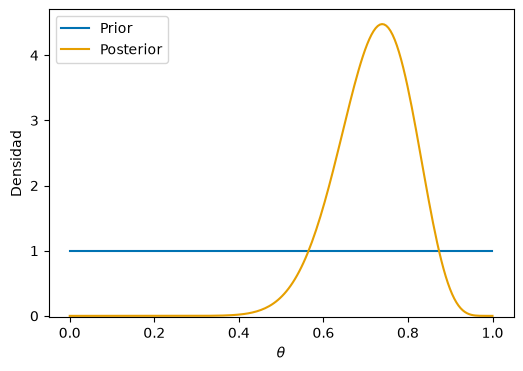

In [4]:
theta_grid = np.linspace(0.0001, 0.9999, 200)
theta_prior_pdf = theta_prior.pdf(theta_grid)
theta_posterior_pdf = theta_posterior.pdf(theta_grid)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(theta_grid, theta_prior_pdf, color=COLORES[0], label="Prior")
ax.plot(theta_grid, theta_posterior_pdf, color=COLORES[1], label="Posterior")
ax.set(ylabel="Densidad", ylim=(-0.025, None))
ax.legend()
ax.set(xlabel=r"$\theta$", ylabel="Densidad");

La función `resumir` usa `.mean()` para la media y `.eti()` para el IC central, como en la notebook anterior.

In [5]:
print("Prior\n-----")
resumir(theta_prior)

print("\nPosterior\n---------")
resumir(theta_posterior);

Prior
-----
Media: 0.5
IC central del 95%: [0.025, 0.975]

Posterior
---------
Media: 0.72
IC central del 95%: [0.533, 0.874]


La media _a posteriori_ es 0.72 y el intervalo central del 95% va de aproximadamente 0.533 a 0.874. Es decir, estimamos una efectividad de 72% y asignamos un 95% de probabilidad al intervalo [53.3%, 87.4%]. Todavía tenemos bastante incertidumbre sobre su efectividad.

### Dos tiros nuevos

¿Cuál es la probabilidad de que Caleb enceste ambos tiros?

Para encontrar la probabilidad de que Caleb Wilson enceste dos tiros libres, tenemos que recurrir a la distribución **predictiva _a posteriori_**. Ahora queremos averiguar cuántos tiros libres podría encestar. Para responder usamos lo que aprendimos sobre $\theta$ y lo combinamos con el modelo para los tiros nuevos (que sigue siendo el de los tiros observados).

La función de masa de la distribución predictiva a _posteriori_ se define:

$$
p(\tilde{y}  \mid  y) = \int p(\tilde{y} \mid \theta) p(\theta \mid y) d\theta
$$

En nuestro modelo esta integral tiene solución analítica y el resultado es la función de masa de probabilidad de una [distribución beta-binomial](https://es.wikipedia.org/wiki/Distribuci%C3%B3n_beta-binomial) de parámetros $\alpha_n$, $\beta_n$ y $m$. Los primeros dos son aquellos de la distribución beta _a posteriori_ y el último es la cantidad de ensayos nuevos.

En cuanto a la probabilidad de interés, la podemos escribir de la siguiente manera:

$$
P(\tilde{Y} = 2 \mid Y = y, m = 2)
$$

Dado $\theta$, la probabilidad de acertar ambos es $\theta^2$. Como no conocemos $\theta$, promediamos sobre su distribución _a posteriori_:

$$
P(\tilde Y=2\mid y,m=2)=\mathbb{E}(\theta^2\mid y)
=\frac{\alpha_n(\alpha_n+1)}{(\alpha_n+\beta_n)(\alpha_n+\beta_n+1)}
=\frac{18\cdot19}{25\cdot26}\approx0.526.
$$

Si fijáramos $\theta$ en su media obtendríamos $0.72^2=0.518$. La diferencia aparece porque estamos promediando sobre un mismo $\theta$ desconocido para ambos tiros. Los tiros son independientes **dado** $\theta$, pero en la predictiva quedan dependientes. Saber que acertó el primero también nos daría información sobre el segundo.

La distribución beta-binomial también está implementada en PreliZ. En `pz.BetaBinomial`, `alpha` y `beta` son los parámetros de la beta _a posteriori_. Por su parte, `n` indica la cantidad de **tiros nuevos**, que en este caso es 2.

Si bien la distribución beta-binomial es discreta, PreliZ llama `.pdf()` al método que calcula las probabilidades puntuales.

Veamos las probabilidades de 0, 1 y 2 aciertos.

In [6]:
# Predictiva para dos tiros nuevos.
y_posterior_predictive = pz.BetaBinomial(
    alpha=alpha_posterior, beta=beta_posterior, n=2
)

# La variable futura solo puede valer 0, 1 o 2.
y_tilde_grid = [0, 1, 2]

# .pdf() devuelve P(Y_tilde=k | datos) para cada entero k.
y_tilde_pmf = y_posterior_predictive.pdf(y_tilde_grid)

Cada bastón muestra la probabilidad de una cantidad posible de aciertos. Esas tres masas deben sumar 1.

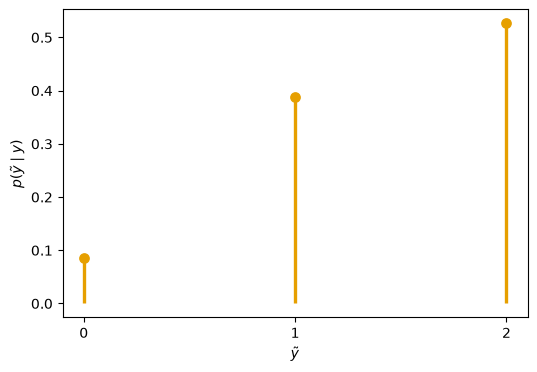

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))

ax.vlines(y_tilde_grid, 0, y_tilde_pmf, color=COLORES[1], linewidth=2.4)
ax.scatter(y_tilde_grid, y_tilde_pmf, color=COLORES[1], s=45, zorder=3)

ax.set(xlabel="$\\tilde{y}$", ylabel="$p(\\tilde{y} \\mid y)$", xticks=[0, 1, 2]);

In [8]:
print("Probabilidades para 0, 1 y 2 aciertos:", np.round(y_tilde_pmf, 3))
print(f"Suma de las probabilidades: {y_tilde_pmf.sum():.2f}")

Probabilidades para 0, 1 y 2 aciertos: [0.086 0.388 0.526]
Suma de las probabilidades: 1.00


Para la pregunta inicial necesitamos la masa en 2. 

Podemos verla en el gráfico, en el mensaje anterior, o también pedirla con `.pdf(2)` y compararla con el resultado de fijar $\theta$ en su media.

In [9]:
probabilidad_dos = y_posterior_predictive.pdf(2)
print(f"Probabilidad de acertar ambos: {probabilidad_dos:.3g}")
print(f"Fijando la probabilidad en la media: {theta_posterior.mean()**2:.3g}")

Probabilidad de acertar ambos: 0.526
Fijando la probabilidad en la media: 0.518


### Obtención de la distribución predictiva _a posteriori_

---

**Demostración**

El modelo para los nuevos tiros y el _posterior_ de $\theta$ se escriben:

$$
\begin{aligned}
\tilde Y\mid\theta&\sim\text{Binomial}(m,\theta),\\
\theta\mid y&\sim\text{Beta}(\alpha_n,\beta_n).
\end{aligned}
$$

y se cuenta con las siguientes funciones de masa de probabilidad y de densidad:

$$
\begin{aligned}
p(\tilde Y=k\mid\theta)&=\binom mk\theta^k(1-\theta)^{m-k},\\
p(\theta\mid y)&=\frac{1}{B(\alpha_n,\beta_n)}\theta^{\alpha_n-1}(1-\theta)^{\beta_n-1}.
\end{aligned}
$$

Para obtener la función de masa de probabilidad predictiva, integramos el producto respecto de $\theta$:

$$
\begin{aligned}
p(\tilde Y=k\mid y)
&=\int_0^1 p(\tilde Y=k\mid\theta)p(\theta\mid y)\,d\theta\\
&=\int_0^1\binom mk\theta^k(1-\theta)^{m-k}
\frac{1}{B(\alpha_n,\beta_n)}\theta^{\alpha_n-1}(1-\theta)^{\beta_n-1}\,d\theta\\
&=\frac{\binom mk}{B(\alpha_n,\beta_n)}
\int_0^1\theta^{\alpha_n+k-1}(1-\theta)^{\beta_n+m-k-1}\,d\theta.
\end{aligned}
$$

La integral que queda es la función beta $B(\alpha_n+k,\beta_n+m-k)$. Luego:

$$p(\tilde Y=k\mid y)=\binom mk\frac{B(\alpha_n+k,\beta_n+m-k)}{B(\alpha_n,\beta_n)},\qquad k=0,\ldots,m,$$

que representa la función de masa de una distribución beta-binomial. Finalmente:

$$\tilde Y\mid y\sim\text{BetaBinomial}(m,\alpha_n,\beta_n).$$

---

Si llamamos $\mu=\alpha_n/(\alpha_n+\beta_n)$ y $s=\alpha_n+\beta_n$, su media y su varianza son:

$$
\mathbb{E}(\tilde Y\mid y)=m\mu,\qquad
\operatorname{Var}(\tilde Y\mid y)=m\mu(1-\mu)\frac{s+m}{s+1}.
$$

Para $m>1$, la varianza es mayor que la de una binomial con probabilidad fija $\mu$. La predictiva incorpora tanto la variabilidad de los tiros como nuestra incertidumbre sobre $\theta$.

### Predictiva a _posteriori_ vs _plug-in_

Suponiendo que los tiros futuros siguen el mismo modelo y son independientes de los anteriores dado $\theta$, el plug-in fija $\theta$ en la media _a posteriori_ y usa $\operatorname{Binomial}(m,0.72)$. La predictiva beta-binomial integra sobre la incertidumbre que queda en $\theta$.

Comparemos las funciones de masa y sus varianzas para 2 y 20 tiros nuevos. La incertidumbre que tenemos sobre $\theta$ suele llamarse epistémica, mientras que la variabilidad de los tiros dado ese parámetro se llama aleatoria. Al usar la predictiva estamos teniendo en cuenta las dos.

2 tiros: varianza plug-in = 0.40 | varianza predictiva = 0.42
20 tiros: varianza plug-in = 4.03 | varianza predictiva = 6.98


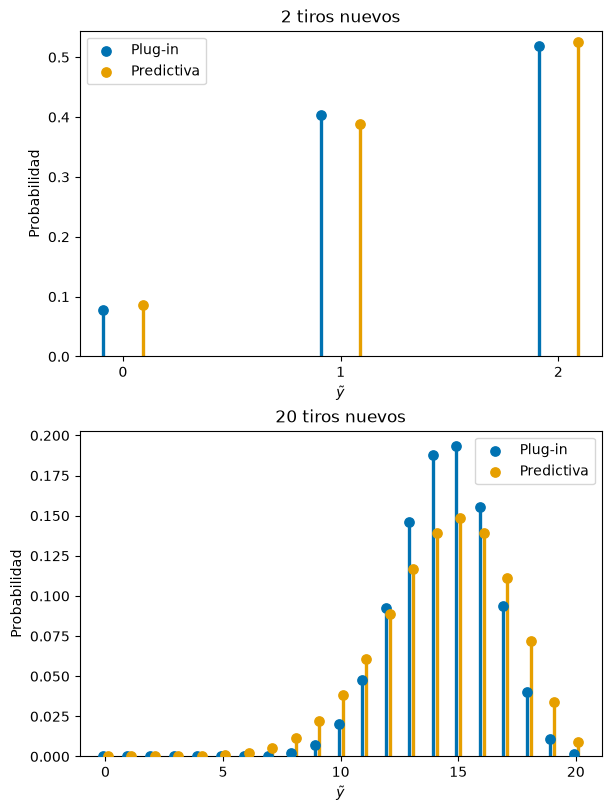

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(6, 8), layout="constrained")

tiros_nuevos = [2, 20]

for ax, m in zip(axes, tiros_nuevos):
    valores = np.arange(m + 1)
    plugin = pz.Binomial(n=m, p=theta_posterior.mean())
    predictiva = pz.BetaBinomial(alpha=alpha_posterior, beta=beta_posterior, n=m)

    # Desplazamos solo los bastones para distinguir masas en el mismo entero.
    probabilidades_plugin = plugin.pdf(valores)
    ax.vlines(valores - 0.09, 0, probabilidades_plugin, color=COLORES[0], linewidth=2.4)
    ax.scatter(
        valores - 0.09,
        probabilidades_plugin,
        color=COLORES[0],
        s=45,
        label="Plug-in",
        zorder=3,
    )
    ax.set(ylabel="Probabilidad", ylim=(0, None))
    probabilidades_predictiva = predictiva.pdf(valores)
    ax.vlines(
        valores + 0.09, 0, probabilidades_predictiva, color=COLORES[1], linewidth=2.4
    )
    ax.scatter(
        valores + 0.09,
        probabilidades_predictiva,
        color=COLORES[1],
        s=45,
        label="Predictiva",
        zorder=3,
    )
    ax.set(ylabel="Probabilidad", ylim=(0, None))
    ax.set(
        xlabel=r"$\tilde y$",
        title=f"{m} tiros nuevos",
        xticks=valores if m == 2 else valores[::5],
    )
    ax.legend()
    print(
        f"{m} tiros: varianza plug-in = {plugin.var():.2f} | "
        f"varianza predictiva = {predictiva.var():.2f}"
    )

De este modo, la probabilidad de que Caleb enceste 2 de 2 tiros nuevos es aproximadamente 52.6%.

A medida que aumenta la cantidad de tiros, acertarlos todos se vuelve menos probable.

Supongamos que en vez de lanzar 2 tiros libres, Caleb lanzara 20. ¿Cuál sería la probabilidad de que acertara más de 15?

Primero creamos la predictiva para 20 tiros y evaluamos su función de masa en los enteros de 0 a 20.

In [11]:
y_posterior_predictive = pz.BetaBinomial(alpha_posterior, beta_posterior, n=20)
y_tilde_grid = np.arange(21)
y_tilde_pmf = y_posterior_predictive.pdf(y_tilde_grid)

Resaltamos los resultados favorables, de 16 a 20 aciertos. El color ayuda a identificar qué masas vamos a sumar.

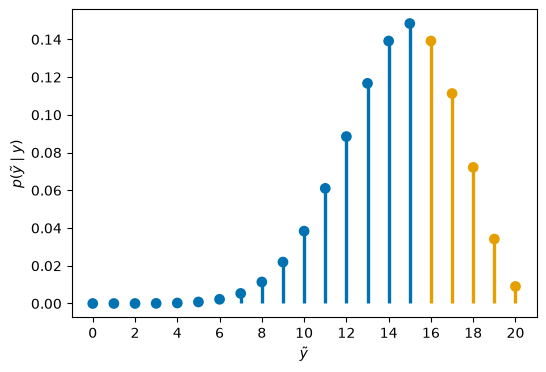

In [12]:
fig, ax = plt.subplots(figsize=(6, 4))
colores_tiros = np.where(y_tilde_grid > 15, COLORES[1], COLORES[0])
ax.vlines(y_tilde_grid, 0, y_tilde_pmf, color=colores_tiros, linewidth=2.4)
ax.scatter(y_tilde_grid, y_tilde_pmf, color=colores_tiros, s=45, zorder=3)
ax.set(
    xlabel="$\\tilde{y}$", ylabel="$p(\\tilde{y} \\mid y)$", xticks=y_tilde_grid[::2]
);

Para obtener $P(\tilde Y>15\mid y)$ usamos el complemento de la CDF en 15. Como la CDF incluye su extremo, al evaluarla en 15 estamos sumando las probabilidades de 0 a 15 aciertos. El complemento reúne entonces las de 16 a 20.

In [13]:
# .cdf(15) suma las masas desde 0 hasta 15, inclusive.
probabilidad_mas_15 = 1 - y_posterior_predictive.cdf(15)
print(f"P(más de 15 aciertos): {probabilidad_mas_15:.3g}")
print(f"P(20 de 20): {y_posterior_predictive.pdf(20):.3g}")
media_theta = theta_posterior.mean()
print(f"Media predictiva: {y_posterior_predictive.mean():.3g}")
print(f"Varianza predictiva: {y_posterior_predictive.var():.3g}")
print(
    f"Varianza binomial con probabilidad fija: {20 * media_theta * (1 - media_theta):.3g}"
)

P(más de 15 aciertos): 0.366
P(20 de 20): 0.00903
Media predictiva: 14.4
Varianza predictiva: 6.98
Varianza binomial con probabilidad fija: 4.03


Sumamos las probabilidades desde 16 hasta 20, porque la pregunta dice **más de 15**:

$$
P(\tilde Y>15\mid y)=\sum_{k=16}^{20}p(\tilde Y=k\mid y)\approx0.366.
$$

La probabilidad de acertar los 20 es mucho menor que la de acertar los dos del ejemplo anterior.

### _Rookie_ contra _rookie_

Cooper Flagg, de los Dallas Mavericks, fue el _rookie_ con más tiros libres convertidos en la temporada regular 2025–2026: **283 aciertos en 342 intentos**.

Si Caleb terminara con 342 intentos en total, ¿qué probabilidad tendría de superar esos 283 aciertos?

Primero podemos hacer una pregunta sobre el parámetro:

¿Cuál es la probabilidad de que $\theta$ supere la proporción observada de Flagg en 2025–26?

Tomamos $\theta_0=283/342\approx0.8275$ como referencia histórica fija. La comparación toma esa proporción como conocida.

Calculamos $P(\theta>\theta_0\mid y)$ usando el complemento de la función de distribución acumulada `.cdf()` de PreliZ.

In [14]:
aciertos_flagg, intentos_flagg = 283, 342
theta_0 = aciertos_flagg / intentos_flagg

# .cdf(theta_0) acumula la probabilidad hasta la referencia.
probabilidad_superar_proporcion = 1 - theta_posterior.cdf(theta_0)
print(f"Proporción de referencia: {theta_0:.3g}")
print(f"P(theta > referencia | y): {probabilidad_superar_proporcion:.3g}")

Proporción de referencia: 0.827
P(theta > referencia | y): 0.105


Obtuvimos una probabilidad de aproximadamente 10.55% para que $\theta$ supere la proporción de referencia. Volvamos ahora a la pregunta sobre la cantidad final de aciertos. Para responderla necesitamos usar la distribución predictiva.

Caleb ya lanzó 23 tiros y convirtió 17. Si termina con 342 intentos, le quedan **319 tiros nuevos**. Sea $\tilde Y$ la cantidad de aciertos en esos tiros:

$$
\tilde Y\mid y\sim\text{BetaBinomial}(319,18,7).
$$

Superar los 283 de Flagg requiere:

$$
17+\tilde Y>283\quad\Longleftrightarrow\quad\tilde Y\ge267.
$$

Necesita al menos 267 nuevos aciertos, para terminar con 284. Por lo tanto:

$$
P(17+\tilde Y>283\mid y)=\sum_{k=267}^{319}p(\tilde Y=k\mid y)=1-F(266).
$$

In [15]:
tiros_restantes = intentos_flagg - n_caleb
minimo_nuevos = aciertos_flagg + 1 - y_caleb
predictiva_temporada = pz.BetaBinomial(
    alpha_posterior, beta_posterior, n=tiros_restantes
)

# Para P(Y_tilde >= 267), complementamos la CDF en 266.
probabilidad_superar_conteo = 1 - predictiva_temporada.cdf(minimo_nuevos - 1)

print(
    f"Intentos restantes: {tiros_restantes}. Aciertos nuevos necesarios: {minimo_nuevos}"
)
print(
    f"Probabilidad de superar los 283 aciertos: {100*probabilidad_superar_conteo:.3g}%"
)

Intentos restantes: 319. Aciertos nuevos necesarios: 267
Probabilidad de superar los 283 aciertos: 9.64%


La probabilidad de que Caleb convierta más tiros libres que Flagg el año anterior, si realiza la misma cantidad de disparos, es de aproximadamente **9.64%**.

Esta probabilidad supone que fijamos la cantidad final de intentos y que el modelo de probabilidad de acierto constante sigue representando los tiros futuros. Por eso, además de actualizar nuestra distribución de $\theta$, tenemos que considerar si esos supuestos son razonables para los tiros que estamos considerando.

# Modelo gamma–Poisson

Hasta acá observamos éxitos en una cantidad fija de intentos. Ahora vamos a trabajar con la **cantidad de eventos en una unidad de exposición**, por ejemplo, llamadas en un día.

**¿Cuál es un modelo observacional posible?** Un conteo puede valer 0, 1, 2, etc. y, según el problema, puede seguir aumentando sin un máximo fijado de antemano. Una opción es la distribución de Poisson:

$$Y_i\mid\lambda\sim\text{Poisson}(\lambda),\qquad\lambda>0.$$

El parámetro $\lambda$ es la cantidad esperada de eventos por unidad de exposición. La media y la varianza de una Poisson son ambas $\lambda$. Suponemos la misma exposición y observaciones independientes dado ese parámetro.

Como en la binomial, podemos distinguir el modelo observacional de la verosimilitud:

$$
\begin{aligned}
p(y_i\mid\lambda)&=\frac{\lambda^{y_i}e^{-\lambda}}{y_i!},\qquad y_i=0,1,\ldots,\\
p(\boldsymbol{y}\mid\lambda)&=\prod_{i=1}^n p(y_i\mid\lambda)
=\frac{\lambda^{\sum_i y_i}e^{-n\lambda}}{\prod_i y_i!}.
\end{aligned}
$$

Para visualizar ambas lecturas vamos a usar primero los datos ilustrativos $\boldsymbol{y}=(1,3,2,4)$. Después pasamos al ejemplo de llamadas.

Primero fijamos $\lambda=3$ y calculamos las probabilidades de los conteos posibles. En PreliZ, `pz.Poisson(mu=...)` recibe la media de la Poisson, que en nuestras ecuaciones llamamos $\lambda$.

In [16]:
conteos_ilustrativos = np.array([1, 3, 2, 4])
conteos = np.arange(11)
modelo_poisson = pz.Poisson(mu=3)
probabilidades_poisson = modelo_poisson.pdf(conteos)

Para la verosimilitud fijamos los datos y variamos $\lambda$. Su núcleo es $\lambda^{10}e^{-4\lambda}$.

El código evalúa la masa Poisson de **cada observación para cada tasa de la grilla**. Con `conteos_ilustrativos[:, None]` ponemos los datos en una columna. Esto permite que, al evaluarlos para todas las tasas, obtengamos una matriz con una fila por observación y una columna por tasa.

Usamos `.logpdf()` para obtener logprobabilidades. Sumar por las filas equivale a multiplicar las probabilidades de las observaciones, pero evita trabajar directamente con productos muy pequeños. `np.exp()` recupera la verosimilitud en su escala original.

In [17]:
lambda_grid = np.linspace(0.001, 9, 800)
modelo_tasas = pz.Poisson(mu=lambda_grid)
# .logpdf() evalúa logmasas: una fila por dato y una columna por tasa.
log_probabilidades = modelo_tasas.logpdf(conteos_ilustrativos[:, None])
log_like_ilustrativa = log_probabilidades.sum(axis=0)
like_ilustrativa = np.exp(log_like_ilustrativa)

Comparemos los dos gráficos. A la izquierda fijamos $\lambda$ y variamos los datos, mientras que a la derecha fijamos los datos y variamos $\lambda$.

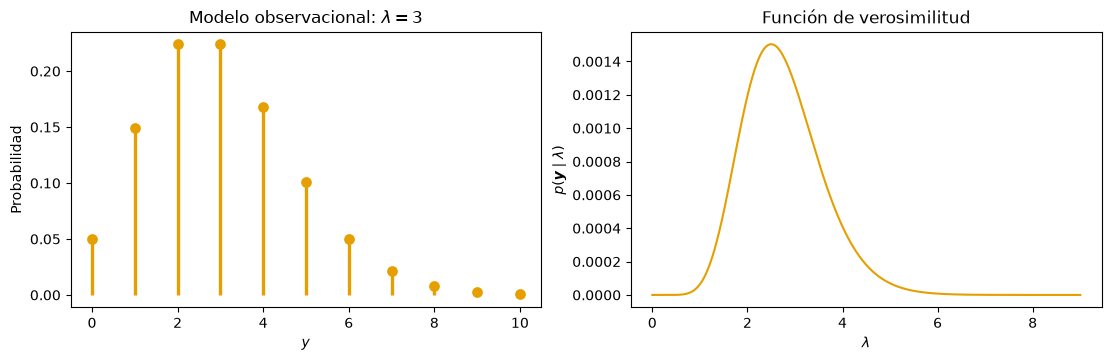

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
axes[0].vlines(conteos, 0, probabilidades_poisson, color=COLORES[1], linewidth=2.4)
axes[0].scatter(conteos, probabilidades_poisson, color=COLORES[1], s=45, zorder=3)
axes[0].set(
    xlabel="$y$", ylabel="Probabilidad", title=r"Modelo observacional: $\lambda=3$"
)
axes[1].plot(lambda_grid, like_ilustrativa, color=COLORES[1])
axes[1].set(
    xlabel=r"$\lambda$",
    ylabel=r"$p(\boldsymbol{y}\mid\lambda)$",
    title="Función de verosimilitud",
);

**¿Cómo representamos la incertidumbre sobre $\lambda$?** Necesitamos una distribución con soporte positivo. Elegimos un _prior_ $\operatorname{Gamma}(\alpha,\beta)$, con **forma–tasa**:

$$p(\lambda)=\frac{\beta^\alpha}{\Gamma(\alpha)}\lambda^{\alpha-1}e^{-\beta\lambda},
\quad\lambda>0,\quad\alpha,\beta>0.$$

Su media es $\alpha/\beta$ y su varianza es $\alpha/\beta^2$.

En esta parametrización $\beta$ es una **tasa**. Esa es también la parametrización de `pz.Gamma(alpha=..., beta=...)` que vamos a usar en PreliZ.

La familia gamma es conjugada para esta verosimilitud. Antes de usarla con datos de llamadas, obtengamos los parámetros del _posterior_.

---

**Demostración**

El modelo conjugado Gamma-Poisson se escribe:

$$
\begin{aligned}
Y_i \mid \lambda &\underset{iid}{\sim} \text{Poisson}(\lambda) & \forall i = 1, \dots, n\\
\lambda &\sim \text{Gamma}(\alpha, \beta)
\end{aligned}
$$

Se cuenta con las siguientes funciones de masa de probabilidad y de densidad:
$$
\begin{aligned}
p(y_i \mid \lambda) &= \frac{e^{-\lambda}\lambda^{y_i}}{y_i!} \\
p(\lambda \mid \alpha, \beta) &= \frac{1}{\Gamma(\alpha)}\lambda^{\alpha - 1}e^{-\beta\lambda}\beta^\alpha
\end{aligned}
$$

La función de verosimilitud resulta:
$$
p(\boldsymbol{y} \mid \lambda) = \prod_{i=1}^n \frac{e^{-\lambda}\lambda^{y_i}}{y_i!} = \frac{e^{-n \lambda}\lambda^{\sum_{i=1}^n y_i}}{\prod_{i=1}^n y_i!}
$$

La densidad _a posteriori_ de $\lambda$ es proporcional al producto de $p(\boldsymbol{y} \mid \lambda)$ y $p(\lambda \mid \alpha, \beta)$:

$$
\begin{aligned}
p(\lambda \mid \boldsymbol{y}) &\propto
    \frac{e^{-n\lambda}\lambda^{\sum_i y_i}}{\prod_i y_i!}
    \frac{1}{\Gamma(\alpha)}\lambda^{\alpha - 1}e^{-\beta\lambda}\beta^\alpha \\
    &= \frac{\beta^\alpha}{\Gamma(\alpha)\prod_i y_i!}
    \lambda^{\alpha-1}\lambda^{\sum_i y_i}e^{-n\lambda}e^{-\beta\lambda} \\
    &= \frac{\beta^\alpha}{\Gamma(\alpha)\prod_i y_i!}
    \lambda^{\sum_i y_i + \alpha -1} e^{-\lambda(n + \beta)}
\end{aligned}
$$

que se puede expresar como:
$$
\begin{aligned}
p(\lambda \mid \boldsymbol{y}) = K^* \lambda^{\sum_i y_i + \alpha -1} e^{-\lambda(n + \beta)}
\end{aligned}
$$

y por condición de cierre de una función de densidad Gamma:
$$
\int_0^{\infty}{K^* \lambda^{\sum_i y_i + \alpha -1} e^{-\lambda(n + \beta)} d\lambda} = 1
$$

se tiene que:
$$
K^* = \frac{(n + \beta)^{\sum_i y_i + \alpha}}{\Gamma(\sum_i y_i + \alpha)}
$$

Finalmente:
$$
\lambda \mid \boldsymbol{y} \sim \text{Gamma}\left(\sum_{i=1}^{n} y_i + \alpha, n + \beta\right)
$$

---

Escribimos los parámetros actualizados como $\alpha_n=\alpha+\sum_i y_i$ y $\beta_n=\beta+n$. La parametrización sigue siendo forma–tasa.

La media permite interpretar el balance de información:

$$\mathbb E(\lambda\mid\boldsymbol{y})
=\frac\beta{\beta+n}\frac\alpha\beta+\frac n{\beta+n}\bar y.$$

$\beta$ actúa como una cantidad de pseudo-observaciones y $\alpha$ como su total de pseudo-eventos, con la unidad de exposición elegida.

## Llamadas sospechosas

Queremos conocer la tasa diaria de llamadas sospechosas. Se registraron conteos en cuatro días de la segunda semana de agosto. Suponemos conteos Poisson independientes dado $\lambda$, con una tasa constante.

Antes de ver esos conteos proponemos $\lambda\sim\operatorname{Gamma}(2,1)$. Veamos qué tasas representa este _prior_.

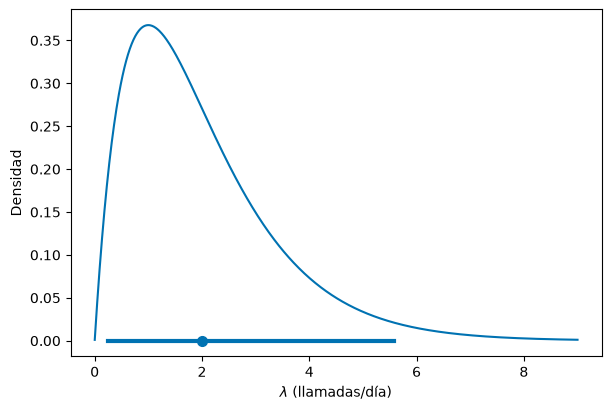

In [19]:
# Forma y tasa del prior; es una elección previa a observar los conteos.
alpha_llamadas = 2
beta_llamadas = 1
prior_llamadas = pz.Gamma(alpha=alpha_llamadas, beta=beta_llamadas)

prior_llamadas_pdf = prior_llamadas.pdf(lambda_grid)

fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")
ax.plot(lambda_grid, prior_llamadas_pdf, color=COLORES[0])
marcar_intervalo(ax, prior_llamadas, COLORES[0])
ax.set(xlabel=r"$\lambda$ (llamadas/día)", ylabel="Densidad");

El segmento marca el IC central del 95% del _prior_ y el punto, su media. Veamos sus valores antes de incorporar las observaciones.

In [20]:
resumir(prior_llamadas);

Media: 2
IC central del 95%: [0.242, 5.57]


Ahora observamos los datos: $\boldsymbol{y}=(6,2,2,1)$. Hay 11 llamadas en 4 días. La actualización da $\operatorname{Gamma}(2+11,1+4)=\operatorname{Gamma}(13,5)$.

In [21]:
y_llamadas = np.array([6, 2, 2, 1])
alpha_n_llamadas = alpha_llamadas + y_llamadas.sum()
beta_n_llamadas = beta_llamadas + y_llamadas.size
posterior_llamadas = pz.Gamma(alpha=alpha_n_llamadas, beta=beta_n_llamadas)

Sumamos 11 eventos a la forma y 4 días a la tasa. Con la distribución _a posteriori_ que acabamos de obtener podemos calcular los resúmenes usando los mismos métodos de PreliZ.

In [22]:
resumir(posterior_llamadas)

Media: 2.6
IC central del 95%: [1.38, 4.19]


Para comparar la actualización, evaluamos la verosimilitud de los conteos y las dos densidades. Los paneles tienen escalas verticales propias porque la verosimilitud conserva la escala del producto de las masas Poisson, mientras que las densidades del _prior_ y del _posterior_ integran 1 respecto de $\lambda$.

In [23]:
log_probabilidades_llamadas = modelo_tasas.logpdf(y_llamadas[:, None])
like_llamadas = np.exp(log_probabilidades_llamadas.sum(axis=0))
prior_llamadas_pdf = prior_llamadas.pdf(lambda_grid)
posterior_llamadas_pdf = posterior_llamadas.pdf(lambda_grid)

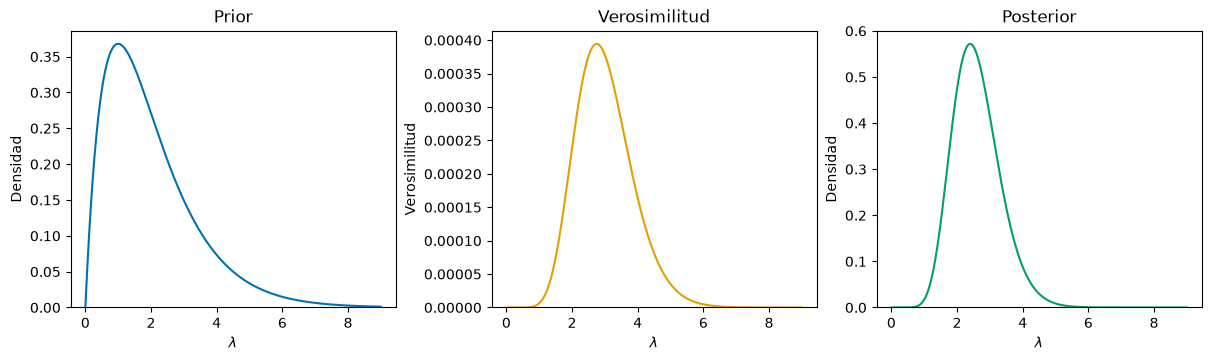

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), layout="constrained")
curvas_llamadas = [
    prior_llamadas_pdf,
    like_llamadas,
    posterior_llamadas_pdf,
]
titulos_llamadas = ["Prior", "Verosimilitud", "Posterior"]
colores_curvas = COLORES[:3]

for ax, valores, titulo, color in zip(
    axes, curvas_llamadas, titulos_llamadas, colores_curvas
):
    ax.plot(lambda_grid, valores, color=color)
    ax.set(title=titulo, xlabel=r"$\lambda$", ylim=(0, None))
    ax.set_ylabel("Verosimilitud" if titulo == "Verosimilitud" else "Densidad")

La media _a posteriori_ es 2.60 llamadas por día. Combina la media _a priori_, 2.00, con la observada, 2.75, con pesos $1/5$ y $4/5$, respectivamente.

# Resúmenes del _posterior_

Tres candidatos para obtener una estimación puntual son la media, mediana y moda.

Cuando la distribución es asimétrica podemos obtener valores diferentes para estos tres resúmenes. La media se obtiene con `.mean()` y, para la mediana, usamos `.ppf(0.5)` porque es el cuantil que deja la mitad de la probabilidad a cada lado. Para esta gamma, con forma mayor que 1, la moda es $(\alpha_n-1)/\beta_n$.

In [25]:
media_llamadas = posterior_llamadas.mean()
# .ppf(0.5) devuelve el cuantil que deja la mitad de la masa a cada lado.
mediana_llamadas = posterior_llamadas.ppf(0.5)
moda_llamadas = (alpha_n_llamadas - 1) / beta_n_llamadas

Ubiquemos los tres valores sobre la misma densidad. Los colores distinguen qué resumen estamos usando.

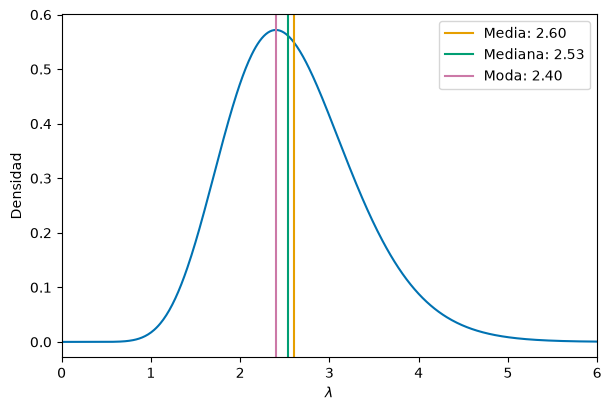

In [26]:
fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")
ax.plot(lambda_grid, posterior_llamadas.pdf(lambda_grid), color=COLORES[0])
estimaciones = [media_llamadas, mediana_llamadas, moda_llamadas]
nombres_estimaciones = ["Media", "Mediana", "Moda"]
colores_estimaciones = COLORES[1:]

for valor, nombre, color in zip(
    estimaciones, nombres_estimaciones, colores_estimaciones
):
    ax.axvline(valor, color=color, label=f"{nombre}: {valor:.2f}")
ax.set(xlabel=r"$\lambda$", ylabel="Densidad", xlim=(0, 6))
ax.legend();

**¿Cuál de esos tres valores conviene elegir?** Depende de cómo midamos el costo de equivocarnos. El riesgo _a posteriori_ es la pérdida esperada bajo el _posterior_:

$$\rho(d\mid\boldsymbol{y})=\mathbb E[L(\lambda,d)\mid\boldsymbol{y}].$$

- La **media** minimiza el riesgo de la pérdida cuadrática, $L(\lambda,d)=(\lambda-d)^2$.
- Una **mediana** minimiza el riesgo de la pérdida absoluta, $L(\lambda,d)=|\lambda-d|$.
- La **moda** maximiza la densidad. Para esta gamma se puede motivar como el límite, al reducir $\epsilon$, de la decisión que minimiza el riesgo de $L_\epsilon(\lambda,d)=\mathbf1\{|\lambda-d|>\epsilon\}$.

Como $\lambda$ es continuo, acertar su valor exacto tiene probabilidad cero. Por eso, para relacionar la moda con una pérdida consideramos un margen de tolerancia $\epsilon$. Cuando ese margen es positivo buscamos el centro del entorno más probable y, para esta gamma, ese centro se acerca a la moda a medida que reducimos $\epsilon$.

## Intervalos de credibilidad

Una estimación puntual deja no refleja la incertidumbre en el _posterior_. Para resumir también esa incertidumbre podemos usar un **IC de nivel $1-a$**, con $0<a<1$:

$$
P(l\leq\lambda\leq u\mid\boldsymbol{y})=\int_l^u p(\lambda\mid\boldsymbol{y})\,d\lambda=1-a.
$$

Podemos construir varios intervalos que contengan esa probabilidad. ¿Cómo elegimos sus extremos?

- El **ETI** deja probabilidad $a/2$ en cada cola: $[Q(a/2),Q(1-a/2)]$. Es el intervalo central que usamos en la notebook 1.
- El **HDI** es el intervalo más corto que contiene la masa elegida. No exige colas con igual probabilidad. En distribuciones multimodales, la región de máxima densidad puede ser disconexa.

Elegimos ahora 95%. PreliZ calcula ambos con `.eti()` y `.hdi()`. Con `mass=0.95` indicamos la probabilidad que deben reunir y, al usar `fmt="none"`, obtenemos extremos numéricos con los que podemos calcular sus longitudes.

In [27]:
eti_llamadas = posterior_llamadas.eti(mass=0.95, fmt="none")
hdi_llamadas = posterior_llamadas.hdi(mass=0.95, fmt="none")
print("ETI 95%:", np.round(eti_llamadas, 2))
print("HDI 95%:", np.round(hdi_llamadas, 2))

ETI 95%: [1.38 4.19]
HDI 95%: [1.28 4.04]


Comparemos también con una $\text{GammaInversa}(2,1)$, un ejemplo independiente de las llamadas. Su cola derecha es más pesada y permite ver mejor la diferencia entre los dos criterios. Al crear una gamma inversa con `pz.InverseGamma`, `alpha` indica la forma y `beta` indica la escala. Si tomamos el recíproco de esa variable obtenemos una gamma con los mismos valores de `alpha` y `beta`, donde `beta` pasa a representar la tasa. Es decir, si $X\sim\text{GammaInversa}(\alpha,\beta)$, entonces $1/X\sim\text{Gamma}(\alpha,\beta)$ con la parametrización forma–tasa que usamos en PreliZ.

In [28]:
cola_pesada = pz.InverseGamma(alpha=2, beta=1)
eti_cola_pesada = cola_pesada.eti(mass=0.95, fmt="none")
hdi_cola_pesada = cola_pesada.hdi(mass=0.95, fmt="none")
intervalos_comparados = [
    (posterior_llamadas, eti_llamadas, hdi_llamadas),
    (cola_pesada, eti_cola_pesada, hdi_cola_pesada),
]

En la figura, los segmentos debajo de cada densidad muestran los dos IC. La leyenda indica sus longitudes. Para poder distinguir los segmentos, los dibujamos un poco por debajo del eje horizontal.

Gamma(13, 5), ETI: [1.38 4.19]; longitud 2.81
Gamma(13, 5), HDI: [1.28 4.04]; longitud 2.76
GammaInversa(2, 1), ETI: [0.18 4.13]; longitud 3.95
GammaInversa(2, 1), HDI: [0.09 2.82]; longitud 2.73


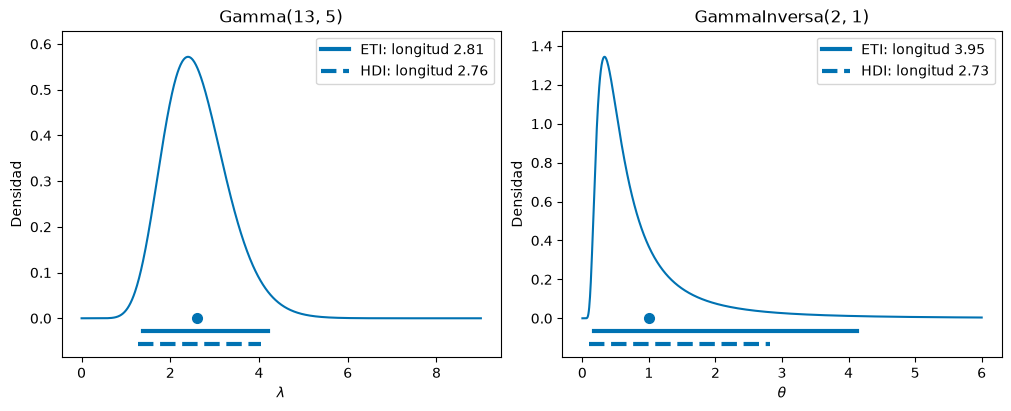

In [29]:
fig, axes_intervalos = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
grillas_intervalos = [lambda_grid, np.linspace(0.001, 6, 1000)]
titulos_intervalos = ["Gamma(13, 5)", "GammaInversa(2, 1)"]
variables_intervalos = [r"$\lambda$", r"$\theta$"]

for ax, (dist, eti, hdi), grilla, titulo, variable in zip(
    axes_intervalos,
    intervalos_comparados,
    grillas_intervalos,
    titulos_intervalos,
    variables_intervalos,
):
    ax.plot(grilla, dist.pdf(grilla), color=COLORES[0])
    altura = dist.pdf(grilla).max()
    intervalos = [eti, hdi]
    niveles_intervalos = [-0.05 * altura, -0.1 * altura]
    nombres_intervalos = ["ETI", "HDI"]
    estilos_intervalos = ["-", "--"]

    for intervalo, nivel, nombre, estilo_linea in zip(
        intervalos, niveles_intervalos, nombres_intervalos, estilos_intervalos
    ):
        longitud = intervalo[1] - intervalo[0]
        ax.plot(
            intervalo,
            [nivel, nivel],
            color=COLORES[0],
            linestyle=estilo_linea,
            linewidth=3,
            markersize=9,
            label=f"{nombre}: longitud {longitud:.2f}",
        )
        print(f"{titulo}, {nombre}: {np.round(intervalo, 2)}; longitud {longitud:.2f}")
    ax.plot(dist.mean(), 0, "o", color=COLORES[0], markersize=7)
    ax.set(
        xlabel=variable,
        ylabel="Densidad",
        title=titulo,
        ylim=(-0.15 * altura, 1.1 * altura),
    )
    ax.set_yticks([tick for tick in ax.get_yticks() if 0 <= tick <= 1.1 * altura])
    ax.legend(loc="upper right", fontsize=10)

La asimetría hace que ETI y HDI tengan extremos y longitudes diferentes. Esta diferencia es más marcada en la gamma inversa.

Acá elegimos entre intervalos que reúnen la misma probabilidad y usamos su longitud como criterio. En la estimación puntual, en cambio, elegimos un valor a partir de la pérdida esperada.

# Modelo normal-normal

## Solo la media desconocida

Ahora la variable observada es una medición continua. Vamos a suponer una distribución normal con media $\mu$ desconocida y **desvío observacional conocido**, $\sigma>0$.

El desvío $\sigma$ describe la variabilidad entre mediciones. La incertidumbre sobre la media necesita su propio modelo. En este caso, elegimos un _prior_ normal. El modelo completo se escribe:

$$
\begin{aligned}
Y_i\mid\mu&\overset{\mathrm{iid}}\sim\operatorname{Normal}(\mu,\sigma^2),\qquad i=1,\ldots,n,\\
\mu&\sim\operatorname{Normal}(\mu_0,\tau_0^2).
\end{aligned}
$$

En las ecuaciones escribimos normal con **media y varianza**. En PreliZ, `sigma` recibe el **desvío**, tanto del modelo observacional como del _prior_.

Para actualizar el _prior_ necesitamos la verosimilitud como función de $\mu$. Primero veamos por qué puede escribirse en términos de la media muestral.

---

**Demostración**

Para observaciones condicionalmente independientes, la función de verosimilitud resulta:

$$p(\boldsymbol{y}\mid\mu)=(2\pi\sigma^2)^{-n/2}
\exp\left[-\frac{\sum_i(y_i-\mu)^2}{2\sigma^2}\right].$$

Escribimos $y_i-\mu=(y_i-\bar y)+(\bar y-\mu)$, expandimos:

$$
\begin{aligned}
\sum_i(y_i-\mu)^2
&=\sum_i(y_i-\bar y)^2
+2(\bar y-\mu)\underbrace{\sum_i(y_i-\bar y)}_{0}
+n(\bar y-\mu)^2\\
&=S+n(\mu-\bar y)^2,\qquad S=\sum_i(y_i-\bar y)^2.
\end{aligned}
$$

$S$ no depende de $\mu$. Manteniendo fijos los datos y $\sigma^2$, los factores $(2\pi\sigma^2)^{-n/2}e^{-S/(2\sigma^2)}$ son constantes. Luego:

$$p(\boldsymbol{y}\mid\mu)\propto_\mu
\exp\left[-\frac n{2\sigma^2}(\mu-\bar y)^2\right].$$

Esta forma normal nos va a permitir reconocer el núcleo del _posterior_ cuando multipliquemos por el _prior_ de $\mu$.

---

Multipliquemos ahora ese núcleo por el _prior_ normal. La siguiente cuenta muestra cómo completar cuadrados permite identificar el _posterior_.

---

**Demostración**

El modelo conjugado Normal–Normal se escribe

$$
\begin{aligned}
Y_i\mid\mu &\underset{iid}{\sim} \text{Normal}(\mu, \sigma^2)  \qquad \forall i = 1, \dots, n\\
\mu &\sim \text{Normal}(\mu_0, \tau_0^2) \\
\end{aligned}
$$

El _posterior_ de $\mu$ es proporcional al producto del _likelihood_

$$
\begin{aligned}
p(\boldsymbol{y} \mid \mu)
    &= \prod_{i=1}^n \frac{1}{\sqrt{2\pi\sigma^2}} \exp \bigg[-\frac{(y_i-\mu)^2}{2\sigma^2}\bigg] \\
    &\propto \exp\bigg[- \frac{(\bar{y} - \mu)^2}{2\sigma^2/n}\bigg]
\end{aligned}
$$

y el _prior_:

$$
\begin{aligned}
p(\mu \mid \mu_0,\tau_0^2)
    &= \frac{1}{\sqrt{2\pi\tau_0^2}} \exp\bigg[-\frac{(\mu-\mu_0)^2}{2\tau_0^2}\bigg] \\
    &\propto \exp\bigg[-\frac{(\mu-\mu_0)^2}{2\tau_0^2}\bigg]
\end{aligned}
$$

Es decir:

$$
p(\mu \mid \boldsymbol{y}) \propto
    \exp\bigg[- \frac{(\bar{y} - \mu)^2}{2\sigma^2/n}\bigg]
    \exp\bigg[-\frac{(\mu-\mu_0)^2}{2\tau_0^2}\bigg]
$$

Expandimos los cuadrados y mandamos a la constante de proporcionalidad el
$\bar{y}^2$ del primer exponente y el $\mu_0^2$ del segundo:

$$
\begin{aligned}
p(\mu \mid \boldsymbol{y})
    &\propto
        \exp\bigg[\frac{-\mu^2 + 2\mu\bar{y} -\bar{y}^2}{2\sigma^2/n} \bigg]
        \exp\bigg[\frac{-\mu^2 + 2\mu\mu_0 -\mu_0^2}{2\tau_0^2} \bigg] \\
    &\propto
        \exp\bigg[\frac{-\mu^2 + 2\mu\bar{y}}{2\sigma^2/n} \bigg]
        \exp\bigg[\frac{-\mu^2 + 2\mu\mu_0}{2\tau_0^2} \bigg]
\end{aligned}
$$

Luego, multiplicamos y dividimos al argumento del primer exponente por $\tau_0^2$ y al del segundo
por $\sigma^2/n$ de modo tal que nos queden ambos con el mismo denominador:

$$
\begin{aligned}
p(\mu \mid \boldsymbol{y})
    &\propto
        \exp\bigg[\frac{(-\mu^2 + 2\mu\bar{y})\tau_0^2}{2\tau_0^2\sigma^2/n} \bigg]
        \exp\bigg[\frac{(-\mu^2 + 2\mu\mu_0)\sigma^2/n}{2\tau_0^2\sigma^2/n} \bigg] \\
    &\propto
        \exp\bigg[\frac{(-\mu^2+2\mu\bar{y})n \tau_0^2 + (-\mu^2 +2\mu\mu_0) \sigma^2}{2\tau_0^2\sigma^2}\bigg]
\end{aligned}
$$

Combinando los términos con $\mu$ y ordenando la expresión para que $\mu^2$ quede por sí mismo:

$$
\begin{aligned}
p(\mu \mid \boldsymbol{y})
    &\propto
        \exp\bigg[\frac{-\mu^2(n\tau_0^2 + \sigma^2) + 2\mu(\mu_0\sigma^2 + \bar{y}n\tau_0^2)}{2\tau_0^2\sigma^2}\bigg] \\
    &\propto
        \exp\bigg[
            \frac{-\mu^2 + 2\mu \left(\frac{\mu_0\sigma^2 + \bar{y}n\tau_0^2}{n\tau_0^2 + \sigma^2}\right)}
            {2(\tau_0^2 \sigma^2) / (n \tau_0^2 + \sigma^2)}
        \bigg]

\end{aligned}
$$

completando cuadrados en el numerador, se llega a:

$$
p(\mu \mid \boldsymbol{y}) \propto
    \exp\bigg[
        \frac{-\left(\mu - \frac{\mu_0\sigma^2 + \bar{y}n\tau_0^2}{n\tau_0^2+\sigma^2}\right)^2}
        {2(\tau_0^2\sigma^2) / (n\tau_0^2 + \sigma^2)}
    \bigg]
$$

que representa el núcleo de una densidad normal para $\mu$. Si definimos

$$
\mu_n=\frac{\mu_0\sigma^2+\bar y n\tau_0^2}{n\tau_0^2+\sigma^2},\qquad
\tau_n^2=\frac{\tau_0^2\sigma^2}{n\tau_0^2+\sigma^2},
$$

su integral respecto de $\mu$ es $\sqrt{2\pi\tau_n^2}$. La constante de normalización es, por lo tanto, $1/\sqrt{2\pi\tau_n^2}$. Luego:

$$
\mu \mid \boldsymbol{y} \sim \text{Normal}\bigg(
    \frac{\mu_0\sigma^2 + \bar{y}n\tau_0^2}{n\tau_0^2 + \sigma^2},
    \frac{\tau_0^2\sigma^2}{n\tau_0^2+\sigma^2}
\bigg)
$$


La media se puede reorganizar para mostrar que es un promedio ponderado entre la media _a priori_ $\mu_0$
y la media muestral $\bar{y}$:

$$
\frac{\mu_0\sigma^2 + \bar{y}n\tau_0^2}{n\tau_0^2 + \sigma^2} =
\mu_0 \frac{\sigma^2}{n\tau_0^2 + \sigma^2} + \bar{y}\frac{n\tau_0^2}{n\tau_0^2 + \sigma^2}
$$

---

Con esta notación, $\mu\mid\boldsymbol{y}\sim\text{Normal}(\mu_n,\tau_n^2)$. Los pesos del promedio anterior dependen de las **precisiones**, inversas de las varianzas. La varianza _a posteriori_ satisface:

$$\frac1{\tau_n^2}=\frac1{\tau_0^2}+\frac n{\sigma^2}.$$

Con $n>0$, es menor que la varianza del _prior_ y que la varianza de la media muestral.

Es útil separar las dos partes de la actualización:

$$\mu_n=\frac{1/\tau_0^2}{1/\tau_0^2+n/\sigma^2}\mu_0
+\frac{n/\sigma^2}{1/\tau_0^2+n/\sigma^2}\bar y.$$

La **media _a posteriori_** combina la media _a priori_ y la media muestral. Cuanto menor es la varianza del _prior_, más peso recibe su media. A su vez, al aumentar la cantidad de observaciones crece el peso de los datos.

La **precisión _a posteriori_** se obtiene sumando las precisiones, de modo que vamos reduciendo la incertidumbre sobre $\mu$. Durante esa actualización seguimos suponiendo conocido el desvío observacional $\sigma$.

## Velocidad de internet

Un proveedor promete una velocidad media de descarga de al menos 20 Mbit/s. Suponemos condiciones estables y mediciones independientes dado $\mu$, con desvío **conocido de 5 Mbit/s**:

$$Y_i\mid\mu\sim\operatorname{Normal}(\mu, 5^2).$$

Antes de ver las mediciones elegimos $\mu\sim\operatorname{Normal}(20,7^2)$: el desvío _a priori_ de la media es **7 Mbit/s**. Describe incertidumbre sobre $\mu$, mientras que 5 describe variabilidad entre mediciones.

In [30]:
# Desvío conocido entre mediciones.
sigma_internet = 5

# Media y varianza del prior de mu, como en las ecuaciones.
mu_0 = 20
tau2_0 = 49

# PreliZ recibe el desvío: sqrt(49)=7.
prior_mu = pz.Normal(mu=mu_0, sigma=np.sqrt(tau2_0))

Comparemos dos distribuciones distintas: el modelo de una medición con $\mu=20$ fijo y el _prior_ sobre la media desconocida. Sus ejes horizontales corresponden a cantidades diferentes, aunque compartan la unidad Mbit/s.

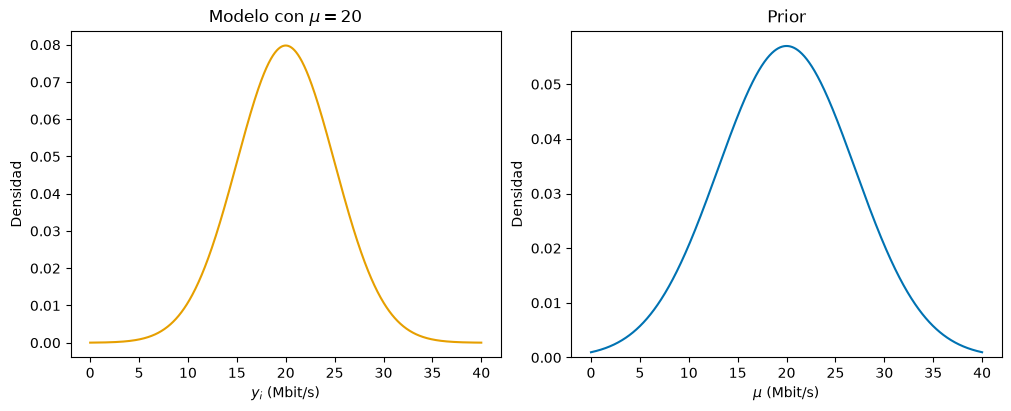

In [31]:
velocidades_grid = np.linspace(0, 40, 1000)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
axes[0].plot(
    velocidades_grid,
    pz.Normal(mu=20, sigma=sigma_internet).pdf(velocidades_grid),
    color=COLORES[1],
)
axes[0].set(xlabel="$y_i$ (Mbit/s)", ylabel="Densidad", title=r"Modelo con $\mu=20$")
axes[1].plot(velocidades_grid, prior_mu.pdf(velocidades_grid), color=COLORES[0])
axes[1].set(xlabel=r"$\mu$ (Mbit/s)", ylabel="Densidad", title="Prior", ylim=(0, None));

Observamos ahora las cinco velocidades: $\boldsymbol{y}=(15.77,20.50,8.26,14.37,21.09)$ Mbit/s. Calculamos con la media sin redondear y sustituimos en las fórmulas anteriores.

In [32]:
y_internet = np.array([15.77, 20.50, 8.26, 14.37, 21.09])
n_internet = y_internet.size


ybar_internet = y_internet.mean()
sigma2_internet = sigma_internet**2

# Sumamos las precisiones para obtener la varianza a posteriori.
tau2_n = 1 / (1 / tau2_0 + n_internet / sigma2_internet)
mu_n = tau2_n * (mu_0 / tau2_0 + n_internet * ybar_internet / sigma2_internet)

# Convertimos la varianza a desvío al crear la normal de PreliZ.
posterior_mu = pz.Normal(mu=mu_n, sigma=np.sqrt(tau2_n))
print(f"Media observada: {ybar_internet:.2f} Mbit/s")
print(f"Media a posteriori: {mu_n:.2f} Mbit/s")
print(
    f"Peso del prior: {tau2_n/tau2_0:.2f}\n"
    f"Peso de los datos: {tau2_n*n_internet/sigma2_internet:.2f}"
)

Media observada: 16.00 Mbit/s
Media a posteriori: 16.37 Mbit/s
Peso del prior: 0.09
Peso de los datos: 0.91


Ya obtuvimos la distribución de $\mu$ _a posteriori_. Para visualizar la actualización, calculamos el producto de las densidades observacionales. Como con Poisson, `.logpdf()` y la suma de logdensidades permiten hacer la cuenta antes de recuperar la escala original con `np.exp()`.

In [33]:
mu_grid = np.linspace(0, 35, 1000)
modelo_mediciones = pz.Normal(mu=mu_grid, sigma=sigma_internet)
log_densidades = modelo_mediciones.logpdf(y_internet[:, None])
like_normal = np.exp(log_densidades.sum(axis=0))
prior_mu_pdf = prior_mu.pdf(mu_grid)
posterior_mu_pdf = posterior_mu.pdf(mu_grid)

Con esas evaluaciones dibujamos _prior_, verosimilitud y _posterior_. Las escalas verticales son independientes.

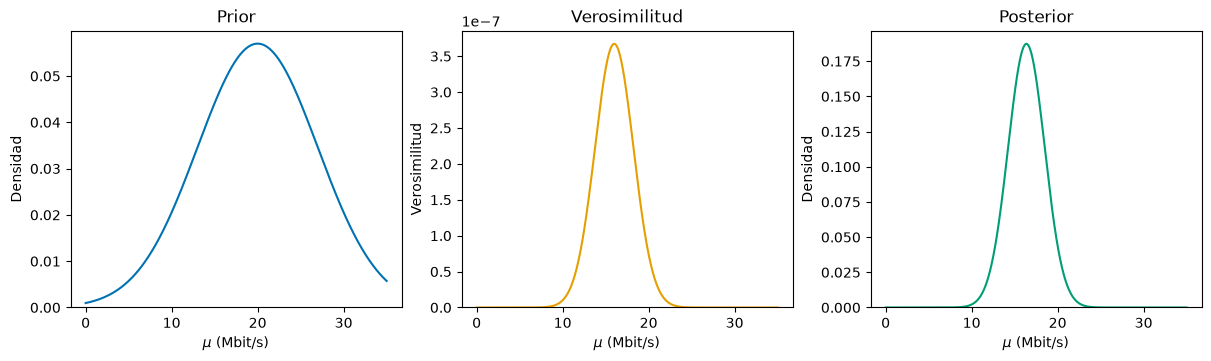

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), layout="constrained")
curvas_mu = [prior_mu_pdf, like_normal, posterior_mu_pdf]
titulos_mu = ["Prior", "Verosimilitud", "Posterior"]
colores_curvas = COLORES[:3]

for ax, valores, titulo, color in zip(axes, curvas_mu, titulos_mu, colores_curvas):
    ax.plot(mu_grid, valores, color=color)
    ax.set(title=titulo, xlabel=r"$\mu$ (Mbit/s)", ylim=(0, None))
    ax.set_ylabel("Verosimilitud" if titulo == "Verosimilitud" else "Densidad")

La media _a posteriori_ queda más cerca de la media muestral porque los datos reciben el 90.74% del peso.

Para evaluar la promesa del proveedor usamos la distribución de $\mu$, su IC y la probabilidad acumulada hasta 20.

La pregunta $P(\mu<20\mid\boldsymbol{y})$ se responde con `.cdf(20)`, que integra la densidad _a posteriori_ hasta 20. Como $\mu$ es continuo, da igual usar $<$ o $\leq$.

In [35]:
ic_mu_normal = posterior_mu.eti(mass=0.95, fmt="none")
probabilidad_mu_menor_20 = posterior_mu.cdf(20)
print("IC central del 95% (Mbit/s):", np.round(ic_mu_normal, 2))
print(f"P(mu < 20 | datos): {probabilidad_mu_menor_20:.2f}")

IC central del 95% (Mbit/s): [12.19 20.54]
P(mu < 20 | datos): 0.96


El área sombreada muestra esa probabilidad. El segmento del eje horizontal es el IC para la media.

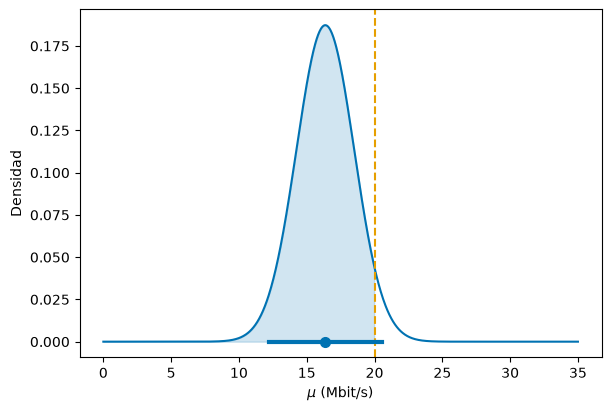

In [36]:
fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")
ax.plot(mu_grid, posterior_mu.pdf(mu_grid), color=COLORES[0])
ax.fill_between(
    mu_grid,
    0,
    posterior_mu.pdf(mu_grid),
    where=mu_grid < 20,
    color=COLORES[0],
    alpha=0.18,
)
marcar_intervalo(ax, posterior_mu, COLORES[0])
ax.axvline(20, color=COLORES[1], linestyle="--")
ax.set(xlabel=r"$\mu$ (Mbit/s)", ylabel="Densidad");

El IC del 95% es [12.19, 20.54] Mbit/s y $P(\mu<20\mid\boldsymbol{y})=0.96$. El intervalo incluye 20 porque deja un 2.5% de probabilidad en cada cola, mientras que por encima de 20 queda aproximadamente un 4.41%. Por la simetría de la normal coinciden la media, la mediana y la moda. Lo mismo ocurre con el ETI y el HDI del mismo nivel.

### Una nueva medición

Suponemos $\tilde Y\mid\mu\sim\operatorname{Normal}(\mu,\sigma^2)$, independiente de las observaciones anteriores dado $\mu$. Ahora integramos el parámetro para predecir.

---

**Demostración**

El modelo para una nueva observación y el _posterior_ de la media se escriben:

$$
\begin{aligned}
\tilde Y\mid\mu&\sim\text{Normal}(\mu,\sigma^2),\\
\mu\mid\boldsymbol{y}&\sim\text{Normal}(\mu_n,\tau_n^2).
\end{aligned}
$$

Se cuenta con las siguientes funciones de densidad:

$$
\begin{aligned}
p(\tilde y\mid\mu)&=\frac1{\sqrt{2\pi\sigma^2}}\exp\left[-\frac{(\tilde y-\mu)^2}{2\sigma^2}\right],\\
p(\mu\mid\boldsymbol{y})&=\frac1{\sqrt{2\pi\tau_n^2}}\exp\left[-\frac{(\mu-\mu_n)^2}{2\tau_n^2}\right].
\end{aligned}
$$

La densidad predictiva se obtiene integrando su producto respecto de $\mu$. Multiplicando y completando cuadrados:

$$
\begin{aligned}
p(\tilde y\mid\boldsymbol{y})&=\frac1{2\pi\sigma\tau_n}
\int_{-\infty}^\infty\exp\left[-\frac12\left\{
\frac{(\tilde y-\mu)^2}{\sigma^2}+\frac{(\mu-\mu_n)^2}{\tau_n^2}\right\}\right]d\mu,\\
\frac{(\tilde y-\mu)^2}{\sigma^2}+\frac{(\mu-\mu_n)^2}{\tau_n^2}
&=A(\mu-h)^2+\frac{(\tilde y-\mu_n)^2}{\sigma^2+\tau_n^2},\\
A&=\frac1{\sigma^2}+\frac1{\tau_n^2},\qquad
h=\frac{\tilde y/\sigma^2+\mu_n/\tau_n^2}{A}.
\end{aligned}
$$

La integral del primer factor exponencial es $\sqrt{2\pi/A}$. Como $\sigma^2\tau_n^2A=\sigma^2+\tau_n^2$,

$$p(\tilde y\mid\boldsymbol{y})=\frac1{\sqrt{2\pi(\sigma^2+\tau_n^2)}}
\exp\left[-\frac{(\tilde y-\mu_n)^2}{2(\sigma^2+\tau_n^2)}\right].$$

Finalmente:

$$\tilde Y\mid\boldsymbol{y}\sim\operatorname{Normal}(\mu_n,\sigma^2+\tau_n^2).$$

---

Su media es $\mu_n$ y su varianza suma la variabilidad entre mediciones, $\sigma^2$, y la incertidumbre sobre la media, $\tau_n^2$. Veamos la diferencia entre inferir la media y predecir una medición.

Para crear la predictiva sumamos la varianza observacional y la varianza _a posteriori_ de la media. Su media es la misma del _posterior_ de $\mu$, pero la nueva observación también varía alrededor de esa media.

In [37]:
varianza_predictiva_normal = sigma2_internet + tau2_n
predictiva_normal = pz.Normal(mu=mu_n, sigma=np.sqrt(varianza_predictiva_normal))
print(f"Varianza predictiva: {predictiva_normal.var():.2f}")
print(f"P(nueva medición < 20 | datos): {predictiva_normal.cdf(20):.2f}")

Varianza predictiva: 29.54
P(nueva medición < 20 | datos): 0.75


Comparemos las dos densidades usando las mismas velocidades para el eje horizontal. El área sombreada corresponde a una pregunta sobre $\mu$ en el primer panel y a una pregunta sobre $\tilde Y$ en el segundo.

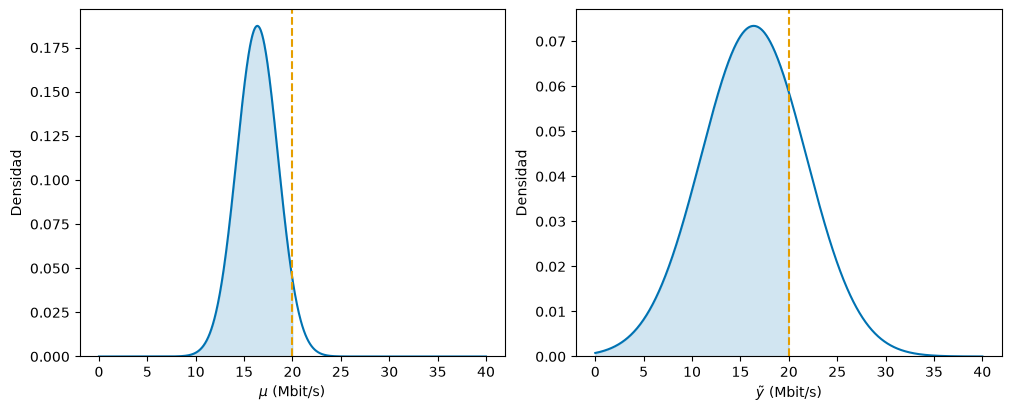

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
distribuciones_normal = [posterior_mu, predictiva_normal]
variables_normal = [r"$\mu$", r"$\tilde y$"]

for ax, dist, variable in zip(axes, distribuciones_normal, variables_normal):
    ax.plot(velocidades_grid, dist.pdf(velocidades_grid), color=COLORES[0])
    ax.fill_between(
        velocidades_grid,
        0,
        dist.pdf(velocidades_grid),
        where=velocidades_grid < 20,
        color=COLORES[0],
        alpha=0.18,
    )
    ax.axvline(20, color=COLORES[1], linestyle="--")
    ax.set(xlabel=variable + " (Mbit/s)", ylabel="Densidad", ylim=(0, None))

La probabilidad de una nueva velocidad menor que 20 es 0.75, frente a 0.96 para la media.

Además de la incertidumbre sobre $\mu$, para una nueva observación tenemos la variabilidad entre mediciones. 

Hasta acá supusimos que su desvío era 5. Ahora vamos a tratarlo también como una cantidad desconocida.

# Media y varianza desconocidas

El modelo observacional sigue siendo normal, pero ahora desconocemos los dos parámetros:

$$Y_i\mid\mu,\sigma^2\overset{\mathrm{iid}}\sim\operatorname{Normal}(\mu,\sigma^2),\qquad
\boldsymbol{\theta}=(\mu,\sigma^2).$$

Un _prior_ es una **distribución bidimensional**, con soporte $\mathbb R\times\mathbb R^+$: $\mu\in\mathbb R$ y $\sigma^2>0$. Cada punto representa una media y una varianza posibles. Por eso vamos a representar la incertidumbre asignando densidad a pares $(\mu,\sigma^2)$.

¿Qué aspecto tiene una distribución sobre esos dos parámetros? Para visualizar ese soporte, mostramos primero un ejemplo de densidad conjunta. La ventana dibujada es finita, aunque el soporte no lo sea.

Para esta primera ilustración elegimos una normal para $\mu$ y una gamma inversa para $\sigma^2$, independientes entre sí. Esta elección nos permite empezar con una conjunta sencilla y después compararla con la familia conjugada.

`np.meshgrid()` construye dos matrices del mismo tamaño, una con las medias de cada punto y otra con sus varianzas. Así podemos evaluar la densidad conjunta en todos los pares de la grilla.

In [39]:
# Densidad ilustrativa para introducir el espacio de dos parámetros.
mu_2d = np.linspace(-5, 45, 240)
sigma2_2d = np.linspace(0.2, 180, 240)
MU_2D, SIGMA2_2D = np.meshgrid(mu_2d, sigma2_2d)
prior_mu_ilustrativo = pz.Normal(mu=20, sigma=7)
prior_sigma2_ilustrativo = pz.InverseGamma(alpha=2.5, beta=73.5)
log_densidad_ilustrativa = prior_mu_ilustrativo.logpdf(
    MU_2D
) + prior_sigma2_ilustrativo.logpdf(SIGMA2_2D)
densidad_ilustrativa = np.exp(log_densidad_ilustrativa)

El color representa la densidad y las líneas blancas unen puntos de igual densidad. Para hacer más visibles las densidades intermedias usamos `PowerNorm` en la escala de colores. Las densidades que calculamos se conservan tal como están.

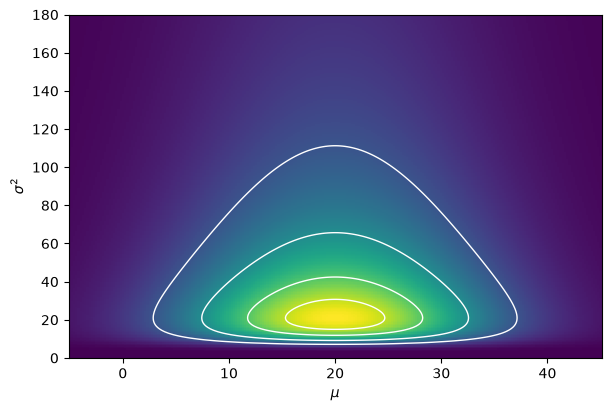

In [40]:
fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")
ax.pcolormesh(
    mu_2d,
    sigma2_2d,
    densidad_ilustrativa,
    cmap="viridis",
    shading="auto",
    norm=PowerNorm(gamma=0.45, vmin=0, vmax=densidad_ilustrativa.max()),
)
ax.contour(
    mu_2d,
    sigma2_2d,
    densidad_ilustrativa,
    levels=densidad_ilustrativa.max() * np.array([0.05, 0.2, 0.5, 0.8]),
    colors="white",
    linewidths=1,
)
ax.set(xlabel=r"$\mu$", ylabel=r"$\sigma^2$", ylim=(0, 180));

## Un _prior_ conjunto

Una opción es elegir _priors_ independientes:

$$p(\mu,\sigma^2)=p(\mu)p(\sigma^2).$$

Esta es la opción que usamos en la ilustración anterior.
Bajo ese supuesto, la distribución _a priori_ de cada componente se mantiene igual cualquiera sea el valor del otro.

Existe también una opción conjugada, la **NormalGammaInversa**:

$$(\mu,\sigma^2)\sim\operatorname{NormalGammaInversa}(m,\kappa,a,b),\qquad
m\in\mathbb R,\quad\kappa,a,b>0.$$

Su densidad es

$$p(\mu,\sigma^2)=\frac{b^a}{\Gamma(a)}\sqrt{\frac\kappa{2\pi}}
(\sigma^2)^{-a-3/2}
\exp\left[-\frac{b+\frac\kappa2(\mu-m)^2}{\sigma^2}\right],\quad\sigma^2>0.$$

- $m$ determina la ubicación de $\mu$.
- $\kappa$ controla la concentración de la media relativa a $\sigma^2$.
- $a$ es la forma de la distribución de la varianza.
- $b$ es su escala: aumentarla con $a$ fijo favorece varianzas mayores.

También es posible representar esa densidad conjunta como el producto de una marginal y una condicional:

$$
\begin{aligned}
\sigma^2&\sim\text{GammaInversa}(a,b),\\
\mu\mid\sigma^2&\sim\operatorname{Normal}(m,\sigma^2/\kappa),\\
p(\mu,\sigma^2)&=p(\mu\mid\sigma^2)p(\sigma^2).
\end{aligned}
$$

La gamma inversa usa **forma–escala**. Al multiplicar sus densidades obtenemos la conjunta anterior. En esta conjunta, la dispersión condicional de $\mu$ depende de $\sigma^2$, por lo que los dos parámetros son dependientes.

Vamos a evaluar la conjunta sumando logdensidades de PreliZ y exponenciando. Las matrices de medias y varianzas permiten evaluar todos los pares de la grilla a la vez. La función siguiente reúne esas dos densidades. Como la varianza de la normal es $\sigma^2/\kappa$, le pasamos `np.sqrt(sigma2 / kappa)` al argumento `sigma`.

In [41]:
def densidad_ngi(mu, sigma2, m, kappa, a, b):
    # Marginal de sigma^2: con parametrización forma–escala.
    log_marginal = pz.InverseGamma(alpha=a, beta=b).logpdf(sigma2)

    # Condicional de mu: el desvío depende de sigma^2.
    log_condicional = pz.Normal(mu=m, sigma=np.sqrt(sigma2 / kappa)).logpdf(mu)

    return np.exp(log_marginal + log_condicional)


def mapa_ngi(ax, mu, sigma2, valores, titulo):
    ax.pcolormesh(
        mu,
        sigma2,
        valores,
        cmap="viridis",
        shading="auto",
        norm=PowerNorm(gamma=0.45, vmin=0, vmax=valores.max()),
    )
    ax.contour(
        mu,
        sigma2,
        valores,
        levels=valores.max() * np.array([0.03, 0.12, 0.3, 0.55, 0.8]),
        colors="white",
        linewidths=1,
    )
    ax.set(title=titulo, xlabel=r"$\mu$", ylabel=r"$\sigma^2$")

Comparemos tres miembros de la familia, cambiando solo su ubicación $m$. Los otros parámetros son los mismos. Cada panel usa su propia escala de color.

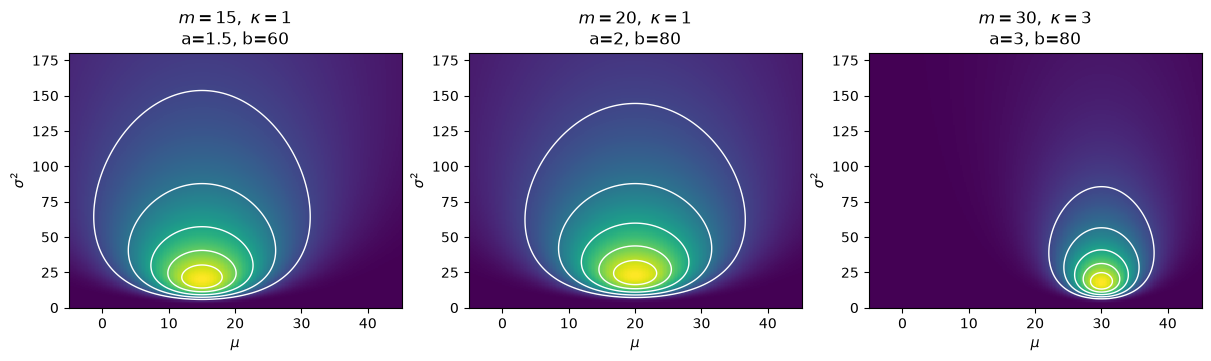

In [42]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), layout="constrained")

medias_prior = [15, 20, 30]
kappas = [1, 1, 3]
a_prior = [1.5, 2, 3]
b_prior = [60, 80, 80]

for ax, m, k, a, b in zip(axes, medias_prior, kappas, a_prior, b_prior):
    densidad = densidad_ngi(MU_2D, SIGMA2_2D, m, k, a, b)
    mapa_ngi(
        ax, mu_2d, sigma2_2d, densidad, rf"$m={m},\ \kappa={k}$" + f"\na={a}, b={b}"
    )

Si $a>1$, $\mathbb E(\sigma^2)=b/(a-1)$ y $\operatorname{Var}(\mu)=b/[\kappa(a-1)]$.

Para internet elegimos $(m_0,\kappa_0,a_0,b_0)=(20,1,2.5,73.5)$. Así $\mathbb E(\sigma^2)=49$ y la marginal de $\mu$ tiene media 20 y varianza 49, como el _prior_ normal anterior. Su forma, sin embargo, será Student-t, con colas más pesadas.

## Actualización conjunta

Como antes, queremos multiplicar la verosimilitud por el _prior_. La diferencia es que ahora ambos dependen de dos parámetros. Vamos a ver cómo el producto conserva la familia NormalGammaInversa.

---

**Demostración**

El modelo conjugado Normal–NormalGammaInversa se escribe:

$$
\begin{aligned}
Y_i\mid\mu,\sigma^2&\underset{iid}{\sim}\text{Normal}(\mu,\sigma^2),\qquad i=1,\ldots,n,\\
(\mu,\sigma^2)&\sim\text{NormalGammaInversa}(m_0,\kappa_0,a_0,b_0).
\end{aligned}
$$

Se cuenta con las siguientes funciones de densidad para los datos y los parámetros:

$$
\begin{aligned}
p(\boldsymbol{y}\mid\mu,\sigma^2)
&=(2\pi\sigma^2)^{-n/2}
\exp\left[-\frac{S+n(\mu-\bar y)^2}{2\sigma^2}\right],\\
p(\mu,\sigma^2)&=\frac{b_0^{a_0}}{\Gamma(a_0)}\sqrt{\frac{\kappa_0}{2\pi}}(\sigma^2)^{-a_0-3/2}
\exp\left[-\frac{b_0+\kappa_0(\mu-m_0)^2/2}{\sigma^2}\right].
\end{aligned}
$$

Usamos la descomposición de suma de cuadrados que ya demostramos. Como ahora $\sigma^2$ es desconocida, conservamos el término $S/(2\sigma^2)$ al multiplicar por el _prior_.

La densidad _a posteriori_ es proporcional al producto de ambas densidades. Multiplicando y ordenando los términos:

$$p(\mu,\sigma^2\mid\boldsymbol{y})\propto
(\sigma^2)^{-(a_0+n/2)-3/2}
\exp\left[-\frac{b_0+S/2+\{n(\mu-\bar y)^2+\kappa_0(\mu-m_0)^2\}/2}{\sigma^2}\right].$$

Para completar cuadrados definimos $\kappa_n=\kappa_0+n$ y $m_n=(\kappa_0m_0+n\bar y)/\kappa_n$. Al expandir ambos lados, obtenemos

$$
\begin{aligned}
n(\mu-\bar y)^2+\kappa_0(\mu-m_0)^2
&=\kappa_n\mu^2-2(\kappa_0m_0+n\bar y)\mu+n\bar y^2+\kappa_0m_0^2\\
&=\kappa_n(\mu-m_n)^2+\frac{\kappa_0n}{\kappa_n}(\bar y-m_0)^2.
\end{aligned}
$$

Sustituimos esa identidad en el producto y definimos

$$
\begin{aligned}
\kappa_n&=\kappa_0+n,\\
m_n&=\frac{\kappa_0m_0+n\bar y}{\kappa_n},\\
a_n&=a_0+\frac n2,\\
b_n&=b_0+\frac S2+\frac{\kappa_0n}{2\kappa_n}(\bar y-m_0)^2.
\end{aligned}
$$

El núcleo queda

$$(\sigma^2)^{-a_n-3/2}
\exp\left[-\frac{b_n+\kappa_n(\mu-m_n)^2/2}{\sigma^2}\right].$$

Esto puede expresarse como una constante $K^*$ multiplicada por ese núcleo. Por condición de cierre de la densidad conjunta, la constante resulta $[b_n^{a_n}/\Gamma(a_n)]\sqrt{\kappa_n/(2\pi)}$: con ella se factoriza en una normal condicional y una gamma inversa marginal, ambas normalizadas. Finalmente:

$$(\mu,\sigma^2)\mid\boldsymbol{y}\sim\operatorname{NormalGammaInversa}(m_n,\kappa_n,a_n,b_n).$$

---

**¿Qué información de los datos necesitamos para actualizar?** Las fórmulas usan el tamaño $n$, la media $\bar y$ y la suma de desvíos cuadrados $S$. Esta última cantidad incorpora la información sobre la dispersión de las observaciones que necesitamos para aprender sobre $\sigma^2$.

Retomemos las cinco mediciones de internet, conservando todos los decimales durante la cuenta.

In [43]:
# Hiperparámetros del prior conjunto.
m_0_ngi = 20
kappa_0_ngi = 1
a_0_ngi = 2.5
b_0_ngi = 73.5
S_internet = np.sum((y_internet - ybar_internet) ** 2)
print(f"n={n_internet}, media={ybar_internet:.2f}, S={S_internet:.2f}")

n=5, media=16.00, S=108.78


Usamos estos resúmenes en las cuatro fórmulas de actualización. `S_internet` es la **suma de cuadrados** que calculamos alrededor de la media muestral. Conservamos todos los decimales de la media para calcular $m_n$ y $b_n$.

In [44]:
kappa_n_ngi = kappa_0_ngi + n_internet
m_n_ngi = (kappa_0_ngi * m_0_ngi + n_internet * ybar_internet) / kappa_n_ngi
a_n_ngi = a_0_ngi + n_internet / 2
b_n_ngi = (
    b_0_ngi
    + S_internet / 2
    + kappa_0_ngi * n_internet / (2 * kappa_n_ngi) * (ybar_internet - m_0_ngi) ** 2
)
print(
    f"m_n={m_n_ngi}, kappa_n={kappa_n_ngi:.2f}, "
    f"a_n={a_n_ngi:.2f}, b_n={b_n_ngi:.2f}"
)

m_n=16.665, kappa_n=6.00, a_n=5.00, b_n=134.56


Comparemos _prior_, verosimilitud y _posterior_ en las mismas coordenadas. Cada panel ajusta los colores al rango de valores de la función que muestra. Esto nos permite ver la forma de las tres funciones. Para comparar sus alturas absolutas tendríamos que usar una misma escala de color. La verosimilitud conserva la escala que obtuvimos al evaluar el modelo en los datos.

Para la verosimilitud conjunta necesitamos una evaluación por cada dato y por cada par de parámetros. Con `y_internet[:, None, None]` agregamos dos ejes a los datos y podemos evaluarlos sobre la grilla de parámetros. Después sumamos sobre `axis=0` para reunir las contribuciones de las cinco mediciones.

In [45]:
mu_comparacion = np.linspace(7, 27, 260)
sigma2_comparacion = np.linspace(0.2, 100, 260)
MU_C, SIGMA2_C = np.meshgrid(mu_comparacion, sigma2_comparacion)

# Prior y posterior evaluados sobre la misma grilla.
prior_conjunto = densidad_ngi(MU_C, SIGMA2_C, m_0_ngi, kappa_0_ngi, a_0_ngi, b_0_ngi)
posterior_conjunto = densidad_ngi(
    MU_C, SIGMA2_C, m_n_ngi, kappa_n_ngi, a_n_ngi, b_n_ngi
)

# Cada observación se evalúa en todos los pares (mu, sigma^2).
modelo_conjunto = pz.Normal(mu=MU_C, sigma=np.sqrt(SIGMA2_C))
log_densidades_conjuntas = modelo_conjunto.logpdf(y_internet[:, None, None])
log_like_conjunta = log_densidades_conjuntas.sum(axis=0)
like_conjunta = np.exp(log_like_conjunta)

Ahora dibujamos esas tres funciones en la misma ventana. El panel del _posterior_ usa los parámetros actualizados que acabamos de calcular.

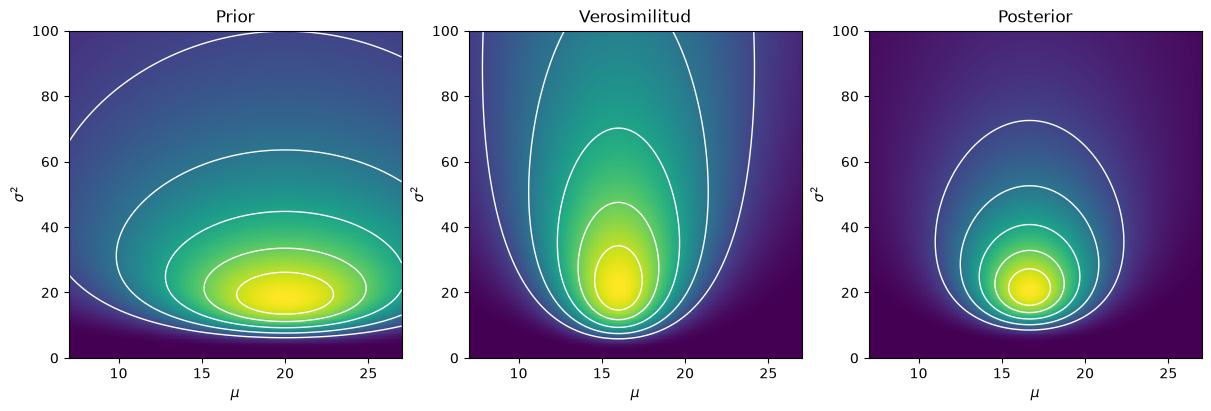

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout="constrained")
densidades = [prior_conjunto, like_conjunta, posterior_conjunto]
titulos = ["Prior", "Verosimilitud", "Posterior"]

for ax, valores, titulo in zip(axes, densidades, titulos):
    mapa_ngi(ax, mu_comparacion, sigma2_comparacion, valores, titulo)
    ax.set(xlim=(7, 27), ylim=(0, 100))

## Marginales

**¿Cómo hacemos inferencia sobre $\mu$ sin fijar un valor de $\sigma^2$?** S
umando toda la incertidumbre que tenemos sobre la varianza. Como es continua, esa suma es una integral. La distribución resultante es la **marginal** de $\mu$.

Para estudiar $\sigma^2$ hacemos lo mismo, integrando $\mu$. La siguiente demostración obtiene ambas distribuciones a partir de la conjunta.

---

**Demostración**

La densidad conjunta _a posteriori_ se puede escribir como $p(\mu\mid\sigma^2,\boldsymbol{y})p(\sigma^2\mid\boldsymbol{y})$. Integrar la normal en $\mu$ da 1, de modo que

$$
\begin{aligned}
p(\sigma^2\mid\boldsymbol{y})
&=\int_{-\infty}^\infty p(\mu,\sigma^2\mid\boldsymbol{y})\,d\mu\\
&=\frac{b_n^{a_n}}{\Gamma(a_n)}(\sigma^2)^{-a_n-1}e^{-b_n/\sigma^2}.
\end{aligned}
$$

Esta expresión representa la densidad de una gamma inversa con forma $a_n$ y escala $b_n$. Luego:

$$\sigma^2\mid\boldsymbol{y}\sim\text{GammaInversa}(a_n,b_n).$$

Para integrar en $\sigma^2$ nos sirve la identidad, válida para $c,q>0$:

$$\int_0^\infty(\sigma^2)^{-q-1}e^{-c/\sigma^2}\,d(\sigma^2)
=c^{-q}\int_0^\infty t^{q-1}e^{-t}\,dt
=\frac{\Gamma(q)}{c^q},\qquad t=\frac c{\sigma^2}.$$

Aplicándola con $q=a_n+1/2$ y $c=b_n+\kappa_n(\mu-m_n)^2/2$, obtenemos

$$
\begin{aligned}
p(\mu\mid\boldsymbol{y})
&=\int_0^\infty p(\mu,\sigma^2\mid\boldsymbol{y})\,d(\sigma^2)\\
&=\frac{b_n^{a_n}\Gamma(a_n+1/2)}{\Gamma(a_n)}\sqrt{\frac{\kappa_n}{2\pi}}
\left[b_n+\frac{\kappa_n}2(\mu-m_n)^2\right]^{-a_n-1/2}\\
&=\frac{\Gamma(a_n+1/2)}{\Gamma(a_n)\sqrt{2\pi b_n/\kappa_n}}
\left[1+\frac{\kappa_n(\mu-m_n)^2}{2b_n}\right]^{-a_n-1/2}.
\end{aligned}
$$

La densidad de una Student-t de grados de libertad $\nu$, ubicación $\ell$ y escala $s>0$ es

$$f(x)=\frac{\Gamma((\nu+1)/2)}{\Gamma(\nu/2)\sqrt{\nu\pi}\,s}
\left[1+\frac{(x-\ell)^2}{\nu s^2}\right]^{-(\nu+1)/2}.$$

Comparando las constantes y las potencias de ambas expresiones, se tiene que $\nu=2a_n$, $\ell=m_n$ y $s^2=b_n/(a_n\kappa_n)$. Finalmente:

$$\mu\mid\boldsymbol{y}\sim\operatorname{StudentT}\left(2a_n,m_n,\sqrt{\frac{b_n}{a_n\kappa_n}}\right).$$

---

El tercer argumento de la Student-t es su **escala** $s$. Para obtener su varianza, cuando $\nu>2$, usamos $\nu s^2/(\nu-2)$. Si aplicamos esta fórmula al _prior_ de $\mu$, obtenemos $b_0/[\kappa_0(a_0-1)]=49$.

En `pz.StudentT`, `nu` indica los grados de libertad, `mu` la ubicación y `sigma` la **escala**. Al usar `sigma` conviene recordar la fórmula de la varianza de la Student-t que acabamos de escribir.

In [47]:
marginal_mu_ngi = pz.StudentT(
    nu=2 * a_n_ngi, mu=m_n_ngi, sigma=np.sqrt(b_n_ngi / (a_n_ngi * kappa_n_ngi))
)
marginal_sigma2_ngi = pz.InverseGamma(alpha=a_n_ngi, beta=b_n_ngi)
prior_marginal_mu_ngi = pz.StudentT(
    nu=2 * a_0_ngi, mu=m_0_ngi, sigma=np.sqrt(b_0_ngi / (a_0_ngi * kappa_0_ngi))
)

Antes de mirar el _posterior_, comprobemos que la normal del caso anterior y la Student-t marginal de este caso tienen la misma media y varianza. Podemos obtener la varianza de las dos distribuciones directamente con `.var()`.

In [48]:
print(f"Prior normal de mu: media {prior_mu.mean():.2f}, varianza {prior_mu.var():.2f}")
print(
    f"Prior Student-t de mu: media {prior_marginal_mu_ngi.mean():.2f}, "
    f"varianza {prior_marginal_mu_ngi.var():.2f}"
)

Prior normal de mu: media 20.00, varianza 49.00
Prior Student-t de mu: media 20.00, varianza 49.00


Las marginales _a posteriori_ permiten ver la incertidumbre de cada componente por separado. Los dos paneles conservan sus soportes y unidades: $\mu$ en Mbit/s y $\sigma^2$ en (Mbit/s)².

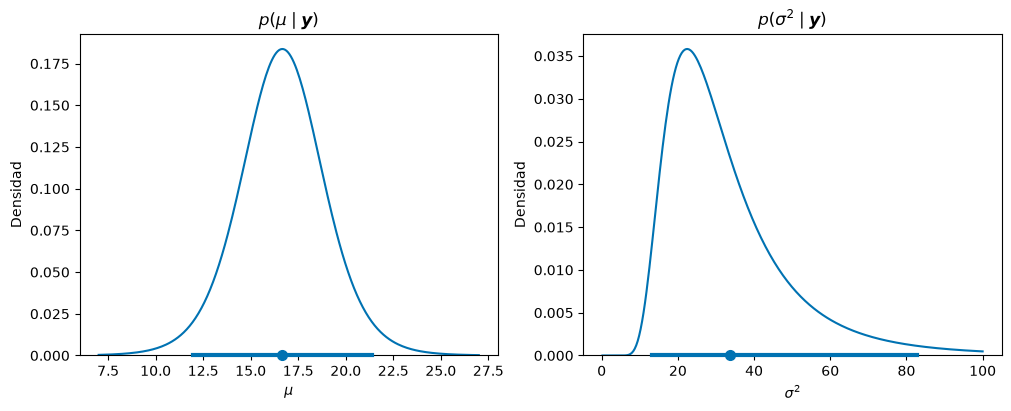

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
grillas_marginales = [mu_comparacion, sigma2_comparacion]
distribuciones_marginales = [marginal_mu_ngi, marginal_sigma2_ngi]
titulos_marginales = [r"$p(\mu\mid\boldsymbol{y})$", r"$p(\sigma^2\mid\boldsymbol{y})$"]
variables_marginales = [r"$\mu$", r"$\sigma^2$"]

for ax, grilla, dist, titulo, variable in zip(
    axes,
    grillas_marginales,
    distribuciones_marginales,
    titulos_marginales,
    variables_marginales,
):
    ax.plot(grilla, dist.pdf(grilla), color=COLORES[0])
    marcar_intervalo(ax, dist, COLORES[0])
    ax.set(title=titulo, xlabel=variable, ylabel="Densidad", ylim=(0, None))

## Condicionales

Una marginal integra la densidad conjunta respecto del otro componente. **¿Qué pasa si, en cambio, fijamos ese componente en un valor?** Obtenemos una distribución condicional.

Por ejemplo, $p(\mu\mid\sigma^2=25,\boldsymbol{y})$ describe la incertidumbre sobre la media suponiendo que la varianza vale 25. En la marginal $p(\mu\mid\boldsymbol{y})$, en cambio, promediamos sobre todos los valores posibles de la varianza. Para obtener las condicionales dividimos los cortes de la conjunta por la densidad marginal correspondiente.

---

**Demostración**

La densidad condicional de $\mu$ se obtiene dividiendo la densidad conjunta por la marginal de $\sigma^2$. Para $\sigma^2=s^2>0$ se tiene:

$$
\begin{aligned}
p(\mu\mid\sigma^2=s^2,\boldsymbol{y})
&=\frac{p(\mu,\sigma^2=s^2\mid\boldsymbol{y})}{p(\sigma^2=s^2\mid\boldsymbol{y})}\\
&=\sqrt{\frac{\kappa_n}{2\pi s^2}}
\exp\left[-\frac{\kappa_n(\mu-m_n)^2}{2s^2}\right].
\end{aligned}
$$

que representa la densidad de una normal con media $m_n$ y varianza $s^2/\kappa_n$. Luego:

$$\mu\mid\sigma^2=s^2,\boldsymbol{y}\sim\text{Normal}(m_n,s^2/\kappa_n).$$

En el cociente evaluamos las densidades en el valor fijado. Así obtenemos el factor que normaliza el corte de la conjunta.

Si fijamos $\mu=m$, dividimos por la marginal Student-t. Ese denominador es constante en $\sigma^2$. El núcleo que queda es

$$(\sigma^2)^{-(a_n+1/2)-1}
\exp\left[-\frac{b_n+\kappa_n(m-m_n)^2/2}{\sigma^2}\right].$$

Definiendo $q=a_n+1/2$ y $c=b_n+\kappa_n(m-m_n)^2/2$, su integral es $\Gamma(q)/c^q$. Finalmente:

$$
\begin{aligned}
p(\sigma^2\mid\mu=m,\boldsymbol{y})
&=\frac{p(\mu=m,\sigma^2\mid\boldsymbol{y})}{p(\mu=m\mid\boldsymbol{y})}\\
&=\frac{c^q}{\Gamma(q)}(\sigma^2)^{-q-1}e^{-c/\sigma^2},\\
\sigma^2\mid\mu=m,\boldsymbol{y}
&\sim\text{GammaInversa}\left(a_n+\frac12,b_n+\frac{\kappa_n}2(m-m_n)^2\right).
\end{aligned}
$$

---


Usemos los cortes ilustrativos $\sigma^2=25$ y $\mu=20$. Las curvas de la derecha muestran las distribuciones condicionales para esos dos valores.

In [50]:
sigma2_fija = 25
mu_fija = 20
condicional_mu = pz.Normal(mu=m_n_ngi, sigma=np.sqrt(sigma2_fija / kappa_n_ngi))
condicional_sigma2 = pz.InverseGamma(
    alpha=a_n_ngi + 0.5, beta=b_n_ngi + kappa_n_ngi * (mu_fija - m_n_ngi) ** 2 / 2
)

Las líneas sobre la conjunta marcan los cortes $\sigma^2=25$ y $\mu=20$. Las curvas de la derecha son esos cortes **normalizados** como densidades condicionales.

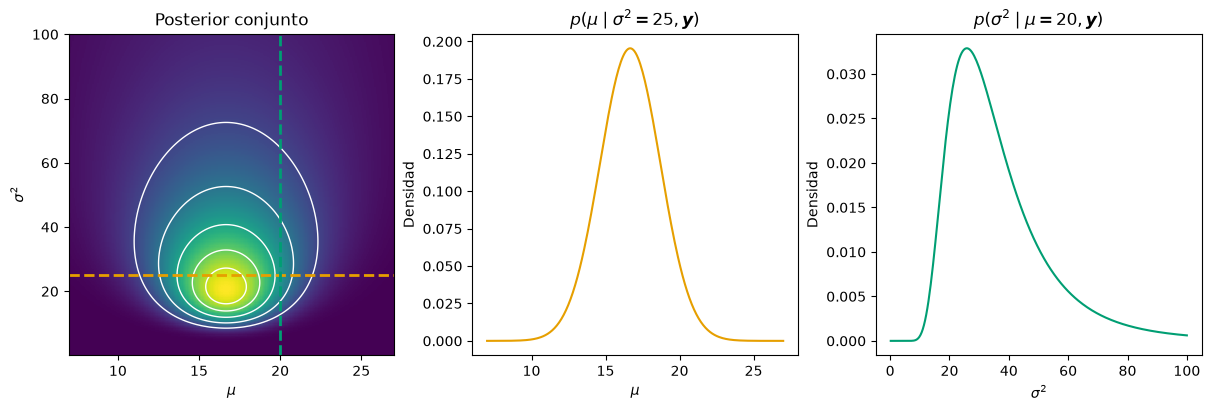

In [51]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout="constrained")
mapa_ngi(
    axes[0],
    mu_comparacion,
    sigma2_comparacion,
    posterior_conjunto,
    "Posterior conjunto",
)
axes[0].axhline(25, color=COLORES[1], linestyle="--", linewidth=2)
axes[0].axvline(20, color=COLORES[2], linestyle="--", linewidth=2)
axes[1].plot(mu_comparacion, condicional_mu.pdf(mu_comparacion), color=COLORES[1])
axes[1].set(
    title=r"$p(\mu\mid\sigma^2=25,\boldsymbol{y})$", xlabel=r"$\mu$", ylabel="Densidad"
)
axes[2].plot(
    sigma2_comparacion, condicional_sigma2.pdf(sigma2_comparacion), color=COLORES[2]
)
axes[2].set(
    title=r"$p(\sigma^2\mid\mu=20,\boldsymbol{y})$",
    xlabel=r"$\sigma^2$",
    ylabel="Densidad",
);

## Inferencias sobre los componentes

Para responder sobre la media o la varianza desconocidas usamos sus **marginales**, que conservan la incertidumbre sobre el otro componente.

Usamos `.eti()` en cada marginal para calcular sus IC y `.cdf(20)` en la marginal de $\mu$ para responder sobre el umbral del proveedor. Condicionar en $\sigma^2=25$ descartaría parte de la incertidumbre que acabamos de modelar.

In [52]:
print("Media poblacional (Mbit/s)")
resumir(marginal_mu_ngi)

print(f"\nP(media < 20 | datos): {marginal_mu_ngi.cdf(20):.2f}")

print("\nVarianza poblacional ((Mbit/s)²)")
resumir(marginal_sigma2_ngi)

Media poblacional (Mbit/s)
Media: 16.7
IC central del 95%: [11.9, 21.4]

P(media < 20 | datos): 0.93

Varianza poblacional ((Mbit/s)²)
Media: 33.6
IC central del 95%: [13.1, 82.9]


La media _a posteriori_ de $\mu$ es 16.67 Mbit/s, con IC [11.95, 21.38]. La media de $\sigma^2$ es 33.64 (Mbit/s)², con IC [13.14, 82.88]. Ahora $P(\mu<20\mid\boldsymbol{y})=0.93$. La comparación con 0.96 del caso anterior refleja tanto desconocer la varianza como cambiar la forma del _prior_ marginal de $\mu$, aun conservando sus dos primeros momentos.

## Predicción con ambos parámetros desconocidos

La nueva observación sigue $\tilde Y\mid\mu,\sigma^2\sim\operatorname{Normal}(\mu,\sigma^2)$ y es independiente de las anteriores dados ambos parámetros. Para obtener la predictiva integramos el **_posterior_ conjunto**, conservando la dependencia entre los parámetros:

$$p(\tilde y\mid\boldsymbol{y})=\int_0^\infty\int_{-\infty}^\infty
p(\tilde y\mid\mu,\sigma^2)p(\mu,\sigma^2\mid\boldsymbol{y})\,d\mu\,d(\sigma^2).$$

---

**Demostración**

El modelo para una nueva observación y el _posterior_ conjunto se escriben:

$$
\begin{aligned}
\tilde Y\mid\mu,\sigma^2&\sim\text{Normal}(\mu,\sigma^2),\\
(\mu,\sigma^2)\mid\boldsymbol{y}&\sim\text{NormalGammaInversa}(m_n,\kappa_n,a_n,b_n).
\end{aligned}
$$

Para obtener la densidad predictiva debemos integrar respecto de ambos parámetros. Primero fijamos $\sigma^2$ y usamos la factorización del _posterior_ conjunto en una normal condicional y una gamma inversa marginal. La integral respecto de $\mu$ resulta:

$$
\begin{aligned}
p(\tilde y\mid\sigma^2,\boldsymbol{y})
&=\int_{-\infty}^\infty p(\tilde y\mid\mu,\sigma^2)
p(\mu\mid\sigma^2,\boldsymbol{y})\,d\mu\\
&=\frac{\sqrt{\kappa_n}}{2\pi\sigma^2}
\int_{-\infty}^\infty
\exp\left[-\frac{(\tilde y-\mu)^2+\kappa_n(\mu-m_n)^2}{2\sigma^2}\right]d\mu.
\end{aligned}
$$

Completamos cuadrados otra vez:

$$(\tilde y-\mu)^2+\kappa_n(\mu-m_n)^2
=(1+\kappa_n)\left(\mu-\frac{\tilde y+\kappa_nm_n}{1+\kappa_n}\right)^2
+\frac{\kappa_n}{1+\kappa_n}(\tilde y-m_n)^2.$$

La integral del término normal en $\mu$ es $\sqrt{2\pi\sigma^2/(1+\kappa_n)}$. Definiendo $c_n=1+1/\kappa_n$, queda

$$p(\tilde y\mid\sigma^2,\boldsymbol{y})=\frac1{\sqrt{2\pi c_n\sigma^2}}
\exp\left[-\frac{(\tilde y-m_n)^2}{2c_n\sigma^2}\right].$$

Esta es una **normal condicionada a $\sigma^2$**, con media $m_n$ y varianza $\sigma^2(1+1/\kappa_n)$. Todavía queda un paso, porque también tenemos incertidumbre sobre la varianza y necesitamos integrarla.

Integramos ahora esa normal contra $\text{GammaInversa}(a_n,b_n)$:

$$
\begin{aligned}
p(\tilde y\mid\boldsymbol{y})
&=\frac{b_n^{a_n}}{\Gamma(a_n)\sqrt{2\pi c_n}}
\int_0^\infty(\sigma^2)^{-a_n-3/2}
\exp\left[-\frac{b_n+(\tilde y-m_n)^2/(2c_n)}{\sigma^2}\right]d(\sigma^2)\\
&=\frac{b_n^{a_n}\Gamma(a_n+1/2)}{\Gamma(a_n)\sqrt{2\pi c_n}}
\left[b_n+\frac{(\tilde y-m_n)^2}{2c_n}\right]^{-a_n-1/2}\\
&=\frac{\Gamma(a_n+1/2)}{\Gamma(a_n)\sqrt{2\pi c_nb_n}}
\left[1+\frac{(\tilde y-m_n)^2}{2c_nb_n}\right]^{-a_n-1/2}.
\end{aligned}
$$

Usamos la identidad gamma de la demostración de marginales. Al comparar con la densidad Student-t, se tiene que $\nu=2a_n$, ubicación $m_n$ y escala $\sqrt{c_nb_n/a_n}$:

Finalmente:

$$\tilde Y\mid\boldsymbol{y}\sim\operatorname{StudentT}\left(
2a_n,m_n,\sqrt{\frac{b_n}{a_n}\left(1+\frac1{\kappa_n}\right)}\right).$$

---

Después de integrar los dos parámetros obtenemos una predictiva **Student-t**. A partir de su escala podemos calcular la varianza, que para $a_n>1$ es $[b_n/(a_n-1)](1+1/\kappa_n)$. En esa expresión se suman la variabilidad esperada de las mediciones y la incertidumbre sobre la media.

Creamos la Student-t con los parámetros de la fórmula. La escala predictiva incluye el factor $1+1/\kappa_n$ porque la nueva medición incorpora variabilidad alrededor de la media, además de la incertidumbre sobre esa media.

In [53]:
grados_libertad_predictiva = 2 * a_n_ngi
escala_predictiva_ngi = np.sqrt(b_n_ngi / a_n_ngi * (1 + 1 / kappa_n_ngi))
predictiva_ngi = pz.StudentT(
    nu=grados_libertad_predictiva, mu=m_n_ngi, sigma=escala_predictiva_ngi
)

In [54]:
print(f"P(media < 20 | datos): {marginal_mu_ngi.cdf(20):.2f}")
print(f"P(nueva medición < 20 | datos): {predictiva_ngi.cdf(20):.2f}")
print(f"Varianza predictiva: {predictiva_ngi.var():.2f}")

P(media < 20 | datos): 0.93
P(nueva medición < 20 | datos): 0.72
Varianza predictiva: 39.25


Comparemos la incertidumbre sobre la media con la distribución de una nueva velocidad. Cada área sombreada responde a su propia pregunta.

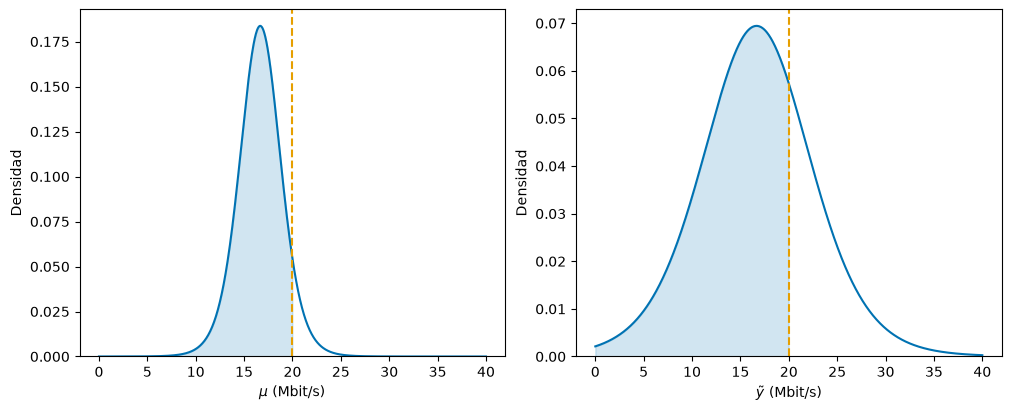

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
distribuciones_predictiva = [marginal_mu_ngi, predictiva_ngi]
variables_predictiva = [r"$\mu$", r"$\tilde y$"]

for ax, dist, variable in zip(axes, distribuciones_predictiva, variables_predictiva):
    ax.plot(velocidades_grid, dist.pdf(velocidades_grid), color=COLORES[0])
    ax.fill_between(
        velocidades_grid,
        0,
        dist.pdf(velocidades_grid),
        where=velocidades_grid < 20,
        color=COLORES[0],
        alpha=0.18,
    )
    ax.axvline(20, color=COLORES[1], linestyle="--")
    ax.set(xlabel=variable + " (Mbit/s)", ylabel="Densidad", ylim=(0, None))

Obtenemos 0.93 para la media y 0.72 para una nueva velocidad. La segunda pregunta incluye variabilidad entre mediciones además de la incertidumbre conjunta sobre los parámetros.

# Ejemplo complementario: enfermedad rara

Queremos estimar la prevalencia $\theta$ de una enfermedad. Suponemos personas independientes dado $\theta$, una misma prevalencia y clasificación sin error, de modo que podemos usar el modelo

$$Y\mid\theta\sim\text{Binomial}(n,\theta).$$

En una muestra de $n=100$ personas encontramos un caso. También vamos a ver qué pasaría si no encontráramos ninguno. Como hay pocos casos, es un ejemplo donde podemos esperar diferencias importantes entre los métodos para construir intervalos.

Por ahora vamos a usar _priors_ sencillos para comparar los procedimientos. Después incorporamos información previa sobre la prevalencia de la enfermedad.

## Comparar intervalos

Vamos a calcular cuatro intervalos del 95% para los mismos datos:

1. **Wald.** Usamos la proporción observada $\hat\theta=y/n$ y la aproximación normal:

   $$I_{\text{Wald}}=\left[\hat\theta-z_{0.975}\sqrt{\frac{\hat\theta(1-\hat\theta)}n},\quad
   \hat\theta+z_{0.975}\sqrt{\frac{\hat\theta(1-\hat\theta)}n}\right].$$

2. **Bayes con _prior_ $\text{Beta}(1,1)$.** Actualizamos el _prior_ uniforme y obtenemos

   $$\theta\mid y\sim\text{Beta}(1+y,1+n-y).$$

   El IC central se obtiene con los cuantiles 0.025 y 0.975 de ese _posterior_.

3. **Wald ajustado «más cuatro».** Sumamos dos casos y dos no casos. La proporción ajustada es $\tilde\theta=(y+2)/(n+4)$ y usamos

   $$I_{+4}=\left[\tilde\theta-z_{0.975}\sqrt{\frac{\tilde\theta(1-\tilde\theta)}{n+4}},\quad
   \tilde\theta+z_{0.975}\sqrt{\frac{\tilde\theta(1-\tilde\theta)}{n+4}}\right].$$

4. **Bayes con _prior_ $\text{Beta}(2,2)$.** En este caso el _posterior_ es

   $$\theta\mid y\sim\text{Beta}(2+y,2+n-y),$$

   y volvemos a usar sus cuantiles 0.025 y 0.975 para construir el IC central.

La media _a posteriori_ del cuarto método es $(y+2)/(n+4)$, por lo que coincide con el centro del intervalo «más cuatro». Los extremos se calculan con procedimientos diferentes y vamos a compararlos en la figura.

Primero calculamos los cuatro intervalos para cada cantidad de casos. El valor $z_{0.975}$ es el cuantil 0.975 de una normal estándar y lo obtenemos con `.ppf(0.975)`. Para los IC beta usamos `.eti(mass=0.95, fmt="none")`, como venimos haciendo.

Guardamos los intervalos y sus centros en el mismo orden en que presentamos los métodos. Mostramos los resultados en porcentajes para poder leer los extremos pequeños.

In [56]:
n_enfermedad = 100
casos_observados = [1, 0]
z_975 = pz.Normal(mu=0, sigma=1).ppf(0.975)

nombres_metodos = [
    "Wald",
    "Bayes - Beta(1, 1)",
    "Wald ajustado (+4)",
    "Bayes - Beta(2, 2)",
]
intervalos_enfermedad = []
centros_enfermedad = []

for casos in casos_observados:
    # Wald a partir de la proporción observada.
    proporcion = casos / n_enfermedad
    semiancho_wald = z_975 * np.sqrt(proporcion * (1 - proporcion) / n_enfermedad)
    wald = proporcion + np.array([-semiancho_wald, semiancho_wald])

    # Ajuste más cuatro: dos casos y dos no casos adicionales.
    proporcion_ajustada = (casos + 2) / (n_enfermedad + 4)
    semiancho_ajustado = z_975 * np.sqrt(
        proporcion_ajustada * (1 - proporcion_ajustada) / (n_enfermedad + 4)
    )
    wald_ajustado = proporcion_ajustada + np.array(
        [-semiancho_ajustado, semiancho_ajustado]
    )

    # Los IC bayesianos se calculan con los cuantiles de cada posterior beta.
    posterior_uniforme = pz.Beta(alpha=1 + casos, beta=1 + n_enfermedad - casos)
    posterior_ajustado = pz.Beta(alpha=2 + casos, beta=2 + n_enfermedad - casos)
    eti_uniforme = posterior_uniforme.eti(mass=0.95, fmt="none")
    eti_ajustado = posterior_ajustado.eti(mass=0.95, fmt="none")

    intervalos_caso = np.array([wald, eti_uniforme, wald_ajustado, eti_ajustado])
    centros_caso = np.array(
        [
            proporcion,
            posterior_uniforme.mean(),
            proporcion_ajustada,
            posterior_ajustado.mean(),
        ]
    )
    intervalos_enfermedad.append(intervalos_caso)
    centros_enfermedad.append(centros_caso)

    print(f"Casos observados: {casos}")
    for nombre, centro, intervalo in zip(
        nombres_metodos, centros_caso, intervalos_caso
    ):
        print(
            f"{nombre}: centro {100 * centro:.2f}%, "
            f"intervalo (%) {np.round(100 * intervalo, 2)}"
        )
    print()

Casos observados: 1
Wald: centro 1.00%, intervalo (%) [-0.95  2.95]
Bayes - Beta(1, 1): centro 1.96%, intervalo (%) [0.24 5.39]
Wald ajustado (+4): centro 2.88%, intervalo (%) [-0.33  6.1 ]
Bayes - Beta(2, 2): centro 2.88%, intervalo (%) [0.6  6.84]

Casos observados: 0
Wald: centro 0.00%, intervalo (%) [0. 0.]
Bayes - Beta(1, 1): centro 0.98%, intervalo (%) [0.03 3.59]
Wald ajustado (+4): centro 1.92%, intervalo (%) [-0.72  4.56]
Bayes - Beta(2, 2): centro 1.92%, intervalo (%) [0.24 5.29]



Ahora podemos comparar todos los métodos en una misma figura. Cada segmento muestra un intervalo y el punto marca su centro. Para los métodos bayesianos usamos la media _a posteriori_.

El eje horizontal muestra la prevalencia como proporción. La línea vertical en cero ayuda a ver cuándo un intervalo incluye valores negativos.

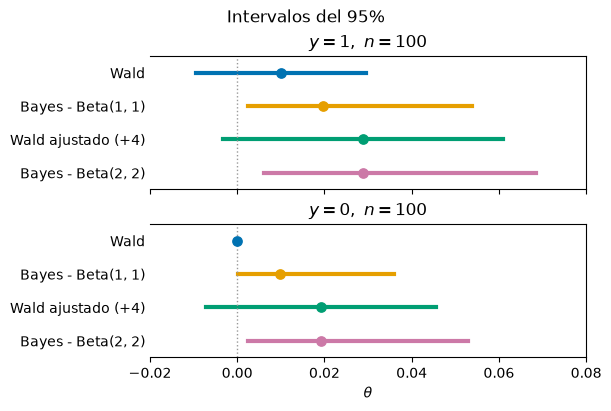

In [57]:
fig, axes = plt.subplots(2, 1, figsize=(6, 4), sharex=True, layout="constrained")
posiciones_metodos = np.arange(len(nombres_metodos))
colores_metodos = COLORES

for ax, casos, intervalos_caso, centros_caso in zip(
    axes, casos_observados, intervalos_enfermedad, centros_enfermedad
):
    for posicion, intervalo, centro, color in zip(
        posiciones_metodos, intervalos_caso, centros_caso, colores_metodos
    ):
        ax.plot(
            intervalo,
            [posicion, posicion],
            color=color,
            linewidth=3,
            markersize=10,
        )
        ax.scatter(centro, posicion, color=color, s=45, zorder=3)

    ax.axvline(0, color="0.6", linestyle=":", linewidth=1)
    ax.set(
        title=rf"$y={casos},\ n={n_enfermedad}$",
        yticks=posiciones_metodos,
        yticklabels=nombres_metodos,
        xlim=(-0.02, 0.08),
        ylim=(len(nombres_metodos) - 0.5, -0.5),
    )
    ax.tick_params(axis="y", length=0)
    ax.spines["left"].set_visible(False)

axes[-1].set_xlabel(r"$\theta$")
fig.suptitle("Intervalos del 95%");

Con un caso, el intervalo de Wald incluye valores negativos y, cuando no encontramos casos, se reduce a [0,0]. El ajuste «más cuatro» desplaza el centro y cambia el ancho, aunque en estos datos también incluye valores negativos. Los IC beta quedan dentro del soporte de la prevalencia y conservan incertidumbre después de observar cero casos.

También podemos ver que los puntos de «más cuatro» y Bayes con _prior_ $\text{Beta}(2,2)$ coinciden, mientras que sus extremos cambian porque uno usa la aproximación normal y el otro usa los cuantiles del _posterior_.

## Elicitar un _prior_ informativo

Hasta acá dejamos afuera la información de que la enfermedad es rara. Para incorporarla necesitamos convertir una afirmación sobre prevalencias plausibles en parámetros de una distribución. Este proceso se llama **elicitación**.

Supongamos ahora que, antes de observar esta muestra, contamos con información que sitúa la prevalencia entre 1% y 10% con probabilidad 95%. Esa información proviene de antes de la muestra con la que vamos a actualizar el _prior_.

Para traducirla a un _prior_ beta exigimos $P(0.01\leq\theta\leq0.10)=0.95$. Entre las betas que cumplen ese requisito, `maxent` busca la de mayor entropía. La probabilidad que queda afuera se reparte entre las dos colas de acuerdo con la distribución obtenida.

También podríamos construir el _prior_ de otra forma, por ejemplo, fijando 2.5% en cada cola para que el intervalo de 1% a 10% sea central. Esa condición adicional conduciría a otros parámetros.

En `pz.maxent`, `lower` y `upper` indican los límites del intervalo, y `mass` su probabilidad. Le pasamos `pz.Beta()` sin parámetros para que los determine y usamos `plot=False` porque vamos a dibujar los _posteriores_ después.

In [58]:
prior_enfermedad_maxent = pz.maxent(
    pz.Beta(), lower=0.01, upper=0.10, mass=0.95, plot=False
)
priors_enfermedad = [
    ("Máxima entropía", prior_enfermedad_maxent),
    ("Uniforme", pz.Beta(alpha=1, beta=1)),
]

Verifiquemos qué restricciones satisface el _prior_ de máxima entropía. La diferencia de CDF entre 0.01 y 0.10 da la masa del intervalo. A través de `.params` obtenemos los parámetros ajustados de PreliZ y los usamos completos para actualizar, aunque los mostremos redondeados.

In [59]:
cola_izquierda = prior_enfermedad_maxent.cdf(0.01)
cola_derecha = 1 - prior_enfermedad_maxent.cdf(0.10)
masa = prior_enfermedad_maxent.cdf(0.10) - prior_enfermedad_maxent.cdf(0.01)

alpha, beta = prior_enfermedad_maxent.params
print(f"alpha={alpha:.2f}, beta={beta:.2f}")
print(f"Masa: {100 * masa:.2f}%")
print(f"cola izquierda: {100 * cola_izquierda:.2f}%")
print(f"cola derecha: {100 * cola_derecha:.2f}%")

inferior, superior = prior_enfermedad_maxent.eti(mass=0.95, fmt="none")
print(f"IC central a priori del 95%: [{100 * inferior:.2f}%, {100 * superior:.2f}%]")

alpha=4.10, beta=75.51
Masa: 95.00%
cola izquierda: 0.68%
cola derecha: 4.32%
IC central a priori del 95%: [1.47%, 10.93%]


Con el _prior_ que obtuvimos mediante `maxent` queda más probabilidad por encima de 0.10 que por debajo de 0.01. Por eso, el intervalo de 1% a 10% contiene el 95% de la probabilidad, pero no es el intervalo central.

Veamos cómo se actualiza este _prior_ con un caso observado en 100 personas y qué pasaría si no hubiéramos encontrado ninguno. Para comparar, actualizamos también el _prior_ uniforme $\operatorname{Beta}(1,1)$ con los mismos datos.

Máxima entropía, casos=1: media 2.84%; IC 95% (%) [0.95 5.71]
Uniforme, casos=1: media 1.96%; IC 95% (%) [0.24 5.39]

Máxima entropía, casos=0: media 2.28%; IC 95% (%) [0.64 4.91]
Uniforme, casos=0: media 0.98%; IC 95% (%) [0.03 3.59]



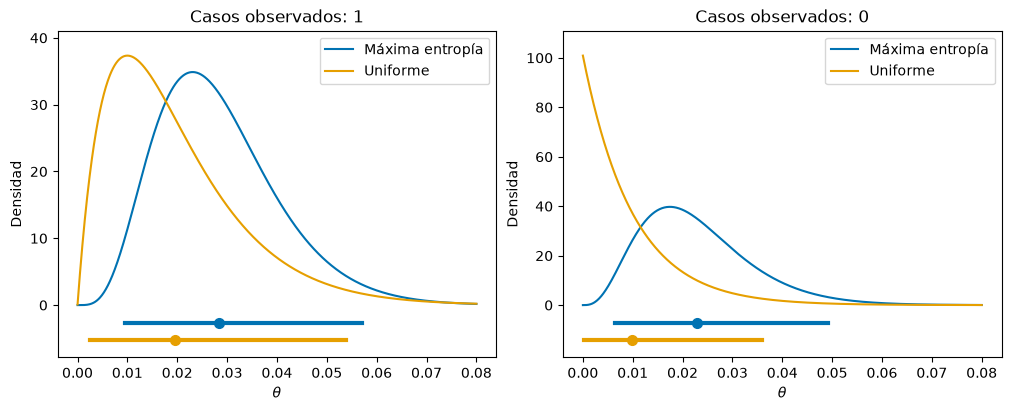

In [60]:
grilla_prevalencia = np.linspace(0.00001, 0.08, 1000)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, layout="constrained")
for ax, casos in zip(axes, casos_observados):
    posteriors = [
        pz.Beta(
            alpha=prior.params[0] + casos, beta=prior.params[1] + n_enfermedad - casos
        )
        for _, prior in priors_enfermedad
    ]
    altura = max(posterior.pdf(grilla_prevalencia).max() for posterior in posteriors)
    for indice, ((nombre, _), posterior, color) in enumerate(
        zip(priors_enfermedad, posteriors, COLORES)
    ):
        ax.plot(
            grilla_prevalencia,
            posterior.pdf(grilla_prevalencia),
            color=color,
            label=nombre,
        )
        eti = np.asarray(posterior.eti(mass=0.95, fmt="none"))
        nivel = -(indice + 1) * 0.07 * altura
        ax.plot(eti, [nivel, nivel], color=color, linewidth=3)
        ax.plot(posterior.mean(), nivel, "o", color=color, markersize=7)
        print(
            f"{nombre}, casos={casos}: media {100*posterior.mean():.2f}%; "
            f"IC 95% (%) {np.round(100*eti, 2)}"
        )
    print()
    ax.set(
        title=f"Casos observados: {casos}",
        xlabel=r"$\theta$",
        ylabel="Densidad",
        ylim=(-0.21 * altura, 1.1 * altura),
    )
    ax.set_yticks([tick for tick in ax.get_yticks() if 0 <= tick <= 1.1 * altura])
    ax.legend()

Usamos los mismos conteos en las dos alternativas, de modo que las diferencias entre los _posteriores_ vienen de la elección del _prior_.

Con un caso, las medias son 2.84% y 1.96% y sin casos, son 2.28% y 0.98%, para los _priors_ de máxima entropía y uniforme, respectivamente.

Los intervalos se superponen, pero la información elicitada desplaza ambos _posteriores_ hacia prevalencias mayores.